# 07. Detección de anomalías (Tarea C)

Entradas: `parte2/salidas/` (lo genera `python -m siata.pipeline` desde `parte2/`): series minutales con la columna `calidad` de SIATA y las banderas propias, y la traza `fallas.parquet` de cada regla que falló.

Salidas versionadas en `parte2/resultados/`: `eventos_anomalias.csv` (tabla de eventos que usa el dashboard), `comparacion_enfoques.csv` y `diccionario_calidad_inferido.csv`. Figuras en `parte2/figuras/07_*.png`.

Orden: C1 reglas deterministas, C2 métodos estadísticos y de aprendizaje automático, C3 comparación con la etiqueta débil, C4 eventos clasificados, C5 banderas y diccionario de códigos.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from siata import anomalias as A
from siata import calidad as Q
from siata.datos import DIR_SALIDAS, ESTACIONES, RAIZ, VARIABLES, agregar, cargar
from siata.indicadores import confiabilidad_bandera, kappa

T0 = time.time()
DIR_RES = RAIZ / "parte2" / "resultados"
DIR_FIG = RAIZ / "parte2" / "figuras"
DIR_FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 120)

# Paleta categórica validada (skill dataviz) y tinta recesiva para ejes y rejilla
AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = ("#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                                               "#e87ba4", "#008300", "#6250d6", "#e34948")
TINTA, TINTA2, GRIS = "#0b0b0b", "#52514e", "#898781"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "font.size": 9, "axes.titlesize": 10,
                     "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA2, "xtick.color": TINTA2,
                     "ytick.color": TINTA2, "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
                     "figure.facecolor": "white", "axes.facecolor": "#fcfcfb", "lines.linewidth": 1.2})


MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]


def fecha(t, hora=False):
    """Fecha en español: 5 mar 2026 (y la hora si se pide)."""
    t = pd.Timestamp(t)
    return f"{t.day} {MESES[t.month - 1]} {t.year}" + (f" {t:%H:%M}" if hora else "")


def eje_fechas(ax, formato="mes"):
    """Etiquetas del eje x en español: 'mes' (dic 2025), 'dia' (5 mar) u 'hora' (14:30)."""
    def f(x, _):
        d = mdates.num2date(x)
        return {"mes": f"{MESES[d.month - 1]} {d.year}", "dia": f"{d.day} {MESES[d.month - 1]}",
                "hora": f"{d:%H:%M}"}[formato]
    ax.xaxis.set_major_formatter(plt.FuncFormatter(f))
    ax.tick_params(axis="x", labelsize=7.5)


def guardar(fig, nombre):
    fig.savefig(DIR_FIG / f"07_{nombre}.png", bbox_inches="tight", pil_kwargs={"optimize": True})
    plt.show()


M = {c: pd.read_parquet(DIR_SALIDAS / f"minutal_{c}.parquet") for c in ESTACIONES}
F = pd.read_parquet(DIR_SALIDAS / "fallas.parquet")
LLUVIA35 = M["35"][["p1", "p2"]].max(axis=1)  # el balancín que más registró: para contexto, no para totales
PERIODO = "1 dic 2025 – 30 abr 2026"
print({c: m.shape for c, m in M.items()}, len(F))

{'367': (217440, 22), '803': (217440, 8), '6004': (217440, 8), '35': (217440, 10)} 21895


## C1. Reglas deterministas

Las reglas están en `siata/calidad.py` (umbrales y su origen en `UMBRALES`). Aquí se resume qué encontró cada una por estación y variable. "Eventos" son minutos contiguos marcados por la misma regla.

In [2]:
# Pruebas que corre calidad.py en cada estación (ver _pruebas_<codigo>); sirve para listar las que no encontraron nada
PRUEBAS_APLICADAS = {
    "367": ["rango_fisico", "rango_clima", "salto", "persistencia", "rafaga_menor", "direccion_sin_viento",
            "viento_cuadruple_cero", "factor_rafaga", "lluvia_no_registrada", "lluvia_sin_respaldo"],
    "803": ["rango_clima", "salto", "persistencia", "pico_sin_lluvia", "sin_contexto"],
    "6004": ["rango_fisico", "radiacion_imposible", "radiacion_extrema", "radiacion_nocturna", "salto", "persistencia"],
    "35": ["rango_fisico", "rango_clima", "resolucion", "p1_p2_difieren"],
}


def contar_eventos(t):
    t = t.sort_values()
    return int((t.diff() != pd.Timedelta("1min")).sum())


resumen = (F.groupby(["codigo", "variable", "prueba", "bandera"])["fecha_hora"]
           .agg(minutos="size", eventos=contar_eventos).reset_index())
con_dato = {(c, v): int(M[c][v].notna().sum()) for c in M for v in ESTACIONES[c]["variables"]}
resumen["pct_minutos_con_dato"] = [100 * r.minutos / con_dato[(r.codigo, r.variable)] if r.prueba != "hueco" else np.nan
                                   for r in resumen.itertuples()]
resumen["bandera"] = resumen["bandera"].map(Q.NOMBRE_BANDERA)
print(resumen.round(3).to_string(index=False))
sin_hallazgos = {c: [p for p in ps if p not in set(F.loc[F.codigo == c, "prueba"])] for c, ps in PRUEBAS_APLICADAS.items()}
print("\nPruebas sin ningún minuto marcado:", sin_hallazgos)

codigo  variable                prueba     bandera  minutos  eventos  pct_minutos_con_dato
    35        p1                 hueco    faltante        7        6                   NaN
    35        p1        p1_p2_difieren  sospechoso      173      119                 0.080
    35        p2                 hueco    faltante        7        6                   NaN
    35        p2        p1_p2_difieren  sospechoso      171      113                 0.079
   367        dv  direccion_sin_viento  sospechoso       21       21                 0.010
   367        dv                 hueco    faltante       43       22                   NaN
   367        dv viento_cuadruple_cero        malo       46       11                 0.021
   367    dv_max                 hueco    faltante       43       22                   NaN
   367    dv_max viento_cuadruple_cero        malo       46       11                 0.021
   367         h                 hueco    faltante       43       22                   NaN

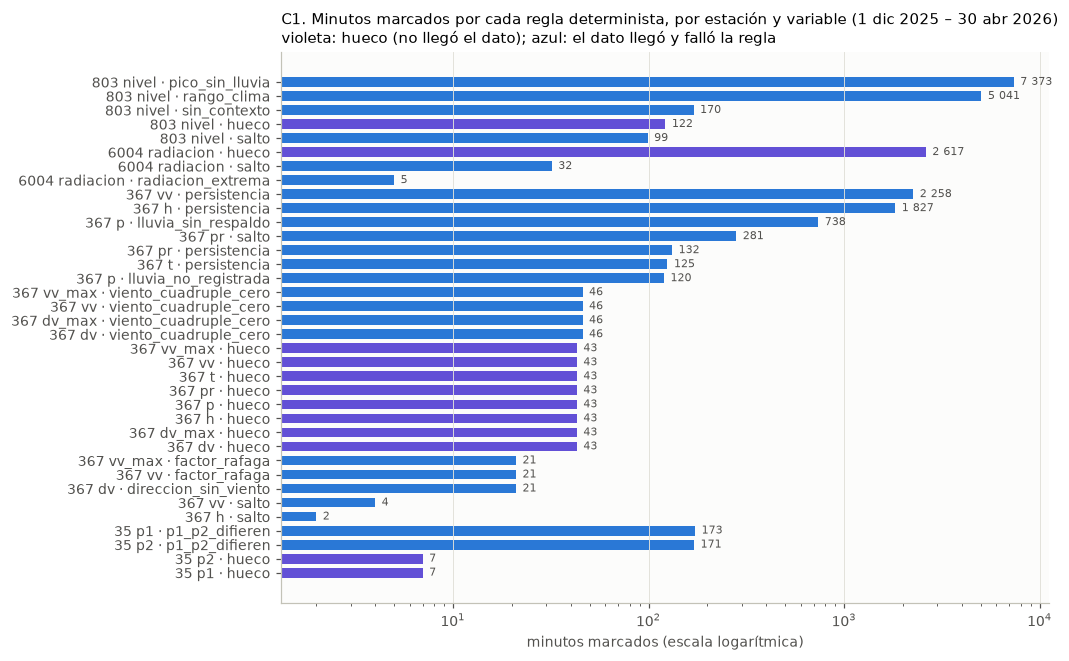

In [3]:
fig, ax = plt.subplots(figsize=(9, 6.5))
r = resumen.groupby(["codigo", "variable", "prueba"], as_index=False)["minutos"].sum()
r["etiqueta"] = r["codigo"] + " " + r["variable"] + " · " + r["prueba"]
r = r.sort_values(["codigo", "minutos"])
color = {"hueco": VIOLETA}
ax.barh(r["etiqueta"], r["minutos"], color=[color.get(p, AZUL) for p in r["prueba"]], height=0.7)
for y, m in enumerate(r["minutos"]):
    ax.text(m * 1.08, y, f"{m:,}".replace(",", " "), va="center", fontsize=7.5, color=TINTA2)
ax.set_xscale("log")
ax.set_xlabel("minutos marcados (escala logarítmica)")
ax.set_title(f"C1. Minutos marcados por cada regla determinista, por estación y variable ({PERIODO})\n"
             "violeta: hueco (no llegó el dato); azul: el dato llegó y falló la regla", loc="left")
ax.grid(axis="y", visible=False)
guardar(fig, "c1_reglas")

### Qué hay detrás de las reglas que más marcan

Antes de clasificar, se revisa cada regla con los datos, para no confundir una falla con un comportamiento real o con un umbral mal puesto.

In [4]:
# 1) Persistencia en la 367: ¿sensor congelado o variable estable?
m367 = M["367"]
filas = []
for v in ("t", "h", "pr", "vv"):
    t = F.loc[(F.codigo == "367") & (F.prueba == "persistencia") & (F.variable == v), "fecha_hora"].sort_values()
    for _, g in t.groupby((t.diff() != pd.Timedelta("1min")).cumsum().to_numpy()):
        x = m367.loc[g.min():g.max()]
        filas.append({"variable": v, "inicio": g.min(), "minutos": len(g), "valores_distintos": x[v].nunique(),
                      "rango": x[v].max() - x[v].min(), "hora": g.min().hour, "h_mediana": x["h"].median(),
                      "lluvia_35_mm": LLUVIA35.loc[g.min():g.max()].sum()})
pers = pd.DataFrame(filas)
print(pers.groupby("variable").agg(eventos=("minutos", "size"), minutos=("minutos", "sum"),
                                   valores_distintos_min=("valores_distintos", "min"),
                                   valores_distintos_mediana=("valores_distintos", "median"),
                                   eventos_entre_19_y_7_h=("hora", lambda h: int(((h >= 19) | (h < 7)).sum())),
                                   con_lluvia=("lluvia_35_mm", lambda s: int((s > 0).sum()))))

# Resolución efectiva: el valor del minuto parece el promedio de lecturas internas de 0,1 °C y 1 %
multiplo = lambda s, paso: float(((s.dropna() / paso).round(6) % 1 == 0).mean())
print("\nfracción de t múltiplo de 0,1 °C:", round(multiplo(m367["t"], 0.1), 3),
      "| fracción de h entera:", round(multiplo(m367["h"], 1), 3),
      "| fracción de pr múltiplo de 0,1 hPa:", round(multiplo(m367["pr"], 0.1), 3))
rachas = {}
for v in ("t", "h", "pr"):
    s = m367[v]
    racha = s.groupby((s != s.shift()).cumsum().to_numpy()).size()
    rachas[v] = int(racha.max())
print("racha más larga con el mismo valor exacto (min):", rachas)

          eventos  minutos  valores_distintos_min  valores_distintos_mediana  eventos_entre_19_y_7_h  con_lluvia
variable                                                                                                        
h              25     1827                      2                        8.0                      25           0
pr              2      132                      5                        7.0                       1           0
t               2      125                      4                        5.5                       2           0
vv             32     2258                     30                       36.0                      25           6

fracción de t múltiplo de 0,1 °C: 0.61 | fracción de h entera: 0.551 | fracción de pr múltiplo de 0,1 hPa: 0.603
racha más larga con el mismo valor exacto (min): {'t': 50, 'h': 145, 'pr': 48}


In [5]:
# 2) Saltos de presión en la 367: caídas de ~1 hPa en un minuto que se recuperan, casi siempre cerca del mediodía
d = m367["pr"].diff()
grandes = d[(d.abs() > Q.UMBRALES["salto"]["pr"]) & (m367.index.to_series().diff() == pd.Timedelta("1min"))]
print("saltos de pr:", len(grandes), "| negativos:", int((grandes < 0).sum()),
      "| entre 9 y 15 h:", int(((grandes.index.hour >= 9) & (grandes.index.hour < 15)).sum()),
      "| días distintos:", grandes.index.normalize().nunique())
print("salto mediano (hPa):", round(grandes.median(), 2), "| viento medio en esos minutos (m/s):",
      round(m367.loc[grandes.index, "vv"].mean(), 2))
# ¿se recupera? fracción del salto que se devuelve en los 5 minutos siguientes
recupera = -(m367["pr"].shift(-5) - m367["pr"]).loc[grandes.index] / grandes
print("fracción del salto recuperada en 5 min: mediana", round(recupera.median(), 2),
      "| saltos que recuperan al menos la mitad:", int((recupera >= 0.5).sum()), "de", len(grandes))
ciclo_pr = m367["pr"].groupby(m367.index.hour).mean()
ritmo = (ciclo_pr.max() - ciclo_pr.min()) / ((ciclo_pr.idxmin() - ciclo_pr.idxmax()) * 60)
print(f"ciclo diurno medio de pr: máximo {ciclo_pr.max():.1f} hPa a las {ciclo_pr.idxmax()} h, mínimo "
      f"{ciclo_pr.min():.1f} hPa a las {ciclo_pr.idxmin()} h; ritmo medio de la bajada {ritmo:.3f} hPa/min; "
      f"salto mediano / ritmo = {abs(grandes.median()) / ritmo:.0f} veces")

# 3) Saltos de radiación en la 6004: ¿de día y con nubes?
m6004 = M["6004"]
SOL = Q.geometria_solar(m6004.index, ESTACIONES["6004"]["lat"], ESTACIONES["6004"]["lon"])
EXTRA = SOL["sa"] * SOL["cos_z"].clip(lower=0)  # radiación extraterrestre sobre superficie horizontal
t = F.loc[(F.codigo == "6004") & (F.prueba == "salto"), "fecha_hora"]
print("\nsaltos de radiación:", len(t), "| elevación solar mínima (°):", round(SOL.loc[t, "elevacion"].min(), 1),
      "| radiación máxima en el salto (W/m²):", m6004.loc[t, "radiacion"].max())

# 4) Saltos del nivel: ¿cuántos están dentro de mesetas o con lluvia?
m803 = M["803"]
lluvia_3h = LLUVIA35.fillna(0).rolling("3h").sum().reindex(m803.index)
t = F.loc[(F.codigo == "803") & (F.prueba == "salto"), "fecha_hora"]
print("\nsaltos del nivel:", len(t), "| con lluvia >= 1 mm en las 3 h previas:", int((lluvia_3h.loc[t] >= 1).sum()),
      "| con nivel > 100 cm a menos de 1 min:",
      int(m803["nivel"].rolling(3, center=True, min_periods=1).max().loc[t].gt(100).sum()))

# 5) Mesetas del nivel (rango climatológico y pico sin lluvia)
t = F.loc[(F.codigo == "803") & F.prueba.isin(["rango_clima", "pico_sin_lluvia"]), "fecha_hora"].drop_duplicates().sort_values()
grupo = (t.diff() > pd.Timedelta("60min")).cumsum().to_numpy()
mesetas = pd.DataFrame([{"inicio": g.min(), "fin": g.max(), "minutos": len(g),
                         "nivel_mediano": m803.loc[g.min():g.max(), "nivel"].median(),
                         "lluvia_3h_previas": LLUVIA35.loc[g.min() - pd.Timedelta("3h"):g.min()].sum(),
                         "pct_siata_dudoso": 100 * A.etiqueta_debil(m803.loc[g, "calidad"]).mean()}
                        for _, g in t.groupby(grupo)])
print(mesetas.round({"nivel_mediano": 1, "lluvia_3h_previas": 1, "pct_siata_dudoso": 1}).to_string(index=False))

saltos de pr: 150 | negativos: 140 | entre 9 y 15 h: 138 | días distintos: 105
salto mediano (hPa): -0.71 | viento medio en esos minutos (m/s): 1.08
fracción del salto recuperada en 5 min: mediana -0.23 | saltos que recuperan al menos la mitad: 4 de 150
ciclo diurno medio de pr: máximo 818.3 hPa a las 8 h, mínimo 813.2 hPa a las 15 h; ritmo medio de la bajada 0.012 hPa/min; salto mediano / ritmo = 58 veces

saltos de radiación: 32 | elevación solar mínima (°): 60.1 | radiación máxima en el salto (W/m²): 1398.27

saltos del nivel: 99 | con lluvia >= 1 mm en las 3 h previas: 11 | con nivel > 100 cm a menos de 1 min: 42
             inicio                 fin  minutos  nivel_mediano  lluvia_3h_previas  pct_siata_dudoso
2025-12-02 18:11:00 2025-12-02 21:36:00      206          246.3                1.0             100.0
2025-12-02 22:42:00 2025-12-03 06:14:00      453          247.0                0.0             100.0
2025-12-03 14:43:00 2025-12-04 14:37:00     1431          244.6         

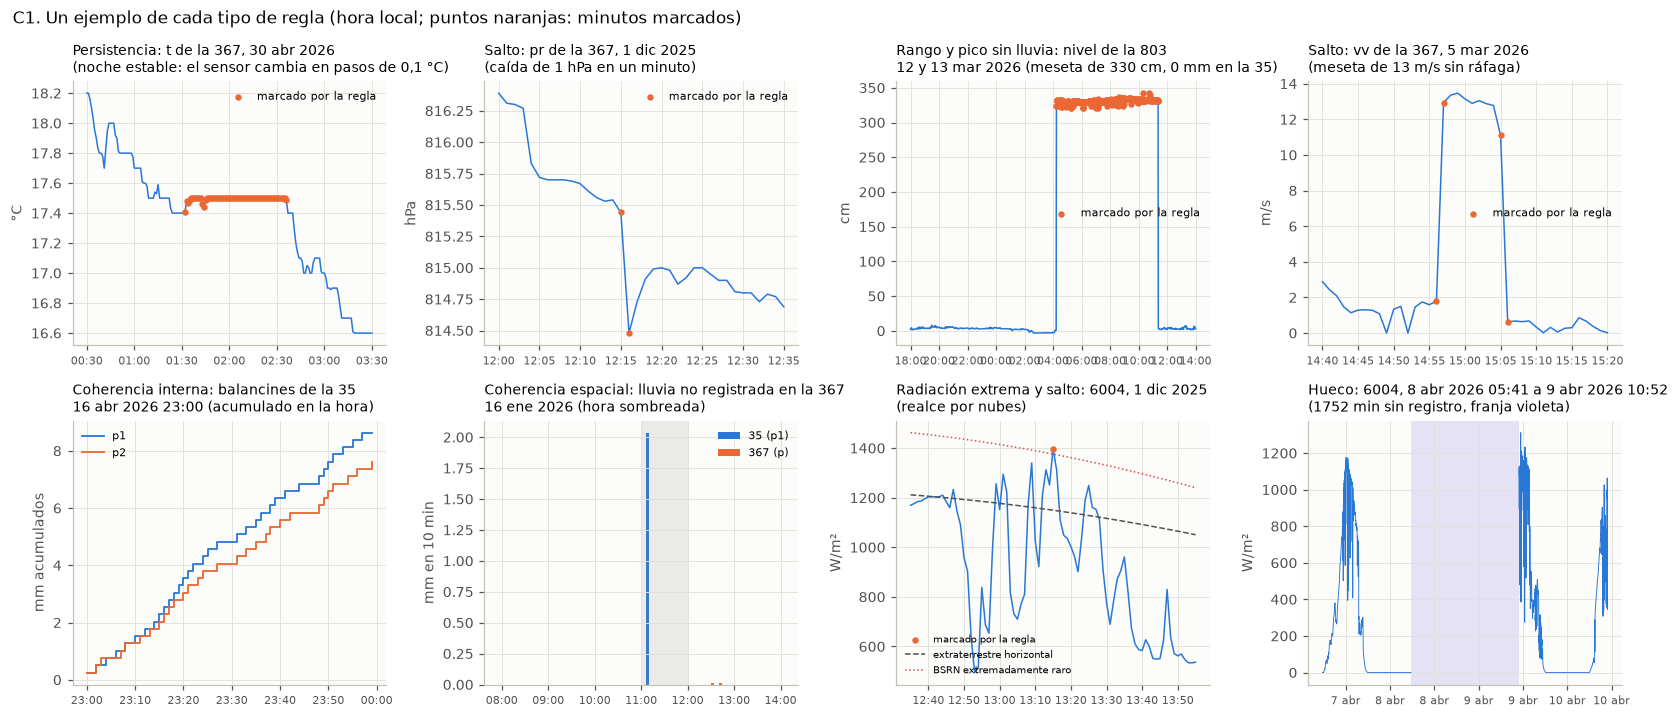

In [6]:
# Ejemplos gráficos de cada tipo de regla, con el dato minutal tal cual (sin interpolar)
def panel(ax, s, marcas, titulo, unidad, color=AZUL, etiqueta=None):
    ax.plot(s.index, s, color=color, lw=1, label=etiqueta)
    m = marcas.reindex(s.index, fill_value=False)
    ax.scatter(s.index[m], s[m], s=10, color=NARANJA, zorder=3, label="marcado por la regla")
    ax.set_title(titulo, loc="left", fontsize=9)
    ax.set_ylabel(unidad)
    eje_fechas(ax, "hora" if s.index[-1] - s.index[0] <= pd.Timedelta("1D") else "dia")


def marca(codigo, prueba, variable=None):
    f = F[(F.codigo == codigo) & (F.prueba == prueba) & ((F.variable == variable) if variable else True)]
    return pd.Series(True, index=pd.DatetimeIndex(f["fecha_hora"].unique()))


fig, axs = plt.subplots(2, 4, figsize=(15, 6.6))
v = slice("2026-04-30 00:30", "2026-04-30 03:30")
panel(axs[0, 0], m367.loc[v, "t"], marca("367", "persistencia", "t"), "Persistencia: t de la 367, 30 abr 2026\n(noche estable: el sensor cambia en pasos de 0,1 °C)", "°C")
v = slice("2025-12-01 12:00", "2025-12-01 12:35")
panel(axs[0, 1], m367.loc[v, "pr"], marca("367", "salto", "pr"), "Salto: pr de la 367, 1 dic 2025\n(caída de 1 hPa en un minuto)", "hPa")
v = slice("2026-03-12 18:00", "2026-03-13 14:00")
panel(axs[0, 2], m803.loc[v, "nivel"], marca("803", "pico_sin_lluvia") | marca("803", "rango_clima"),
      "Rango y pico sin lluvia: nivel de la 803\n12 y 13 mar 2026 (meseta de 330 cm, 0 mm en la 35)", "cm")
v = slice("2026-03-05 14:40", "2026-03-05 15:20")
panel(axs[0, 3], m367.loc[v, "vv"], marca("367", "salto", "vv"), "Salto: vv de la 367, 5 mar 2026\n(meseta de 13 m/s sin ráfaga)", "m/s")
# coherencia interna en la 35: acumulado de cada balancín en una hora marcada
f = F[(F.codigo == "35") & (F.prueba == "p1_p2_difieren")]
hora = f["fecha_hora"].dt.floor("h").value_counts().idxmax()
x = M["35"].loc[hora:hora + pd.Timedelta("59min"), ["p1", "p2"]].cumsum()
axs[1, 0].step(x.index, x["p1"], where="post", color=AZUL, label="p1")
axs[1, 0].step(x.index, x["p2"], where="post", color=NARANJA, label="p2")
axs[1, 0].set_title(f"Coherencia interna: balancines de la 35\n{fecha(hora, True)} (acumulado en la hora)", loc="left", fontsize=9)
axs[1, 0].set_ylabel("mm acumulados"); axs[1, 0].legend(fontsize=7)
eje_fechas(axs[1, 0], "hora")
# coherencia espacial: lluvia horaria de la 35 frente a la 367 en la hora marcada
f = F[(F.codigo == "367") & (F.prueba == "lluvia_no_registrada")]
h0 = f["fecha_hora"].min().floor("h")
v = slice(h0 - pd.Timedelta("3h"), h0 + pd.Timedelta("3h"))
q = pd.DataFrame({"35 (p1)": M["35"].loc[v, "p1"].resample("10min").sum(), "367 (p)": m367.loc[v, "p"].resample("10min").sum()})
axs[1, 1].bar(q.index - pd.Timedelta("2min"), q["35 (p1)"], width=pd.Timedelta("4min"), color=AZUL, label="35 (p1)")
axs[1, 1].bar(q.index + pd.Timedelta("2min"), q["367 (p)"], width=pd.Timedelta("4min"), color=NARANJA, label="367 (p)")
axs[1, 1].axvspan(h0, h0 + pd.Timedelta("1h"), color=GRIS, alpha=0.15, lw=0)
axs[1, 1].set_title(f"Coherencia espacial: lluvia no registrada en la 367\n{fecha(h0)} (hora sombreada)", loc="left", fontsize=9)
axs[1, 1].set_ylabel("mm en 10 min"); axs[1, 1].legend(fontsize=7)
eje_fechas(axs[1, 1], "hora")
# radiación: salto y límite BSRN
t = F.loc[(F.codigo == "6004") & (F.prueba == "radiacion_extrema"), "fecha_hora"].min()
v = slice(t - pd.Timedelta("40min"), t + pd.Timedelta("40min"))
posible, raro = Q.limites_bsrn(SOL)
panel(axs[1, 2], m6004.loc[v, "radiacion"], marca("6004", "radiacion_extrema") | marca("6004", "salto"),
      f"Radiación extrema y salto: 6004, {fecha(t)}\n(realce por nubes)", "W/m²")
axs[1, 2].plot(EXTRA.loc[v].index, EXTRA.loc[v], color=TINTA2, ls="--", lw=1, label="extraterrestre horizontal")
axs[1, 2].plot(raro.loc[v].index, raro.loc[v], color=ROJO, ls=":", lw=1, label="BSRN extremadamente raro")
axs[1, 2].legend(fontsize=6.5, loc="lower left")
# hueco: el más largo de la 6004
falta = m6004["radiacion"].isna()
grupo = (falta != falta.shift()).cumsum()
largo = falta.groupby(grupo).sum().idxmax()
g = m6004.index[(grupo == largo).to_numpy()]
v = slice(g.min() - pd.Timedelta("1D"), g.max() + pd.Timedelta("1D"))
axs[1, 3].plot(m6004.loc[v].index, m6004.loc[v, "radiacion"], color=AZUL, lw=0.6)
axs[1, 3].axvspan(g.min(), g.max(), color=VIOLETA, alpha=0.15, lw=0)
axs[1, 3].set_title(f"Hueco: 6004, {fecha(g.min(), True)} a {fecha(g.max(), True)}\n({len(g)} min sin registro, franja violeta)", loc="left", fontsize=9)
axs[1, 3].set_ylabel("W/m²"); eje_fechas(axs[1, 3], "dia")
for ax in axs[0]:
    ax.legend(fontsize=7, loc="best")
fig.suptitle("C1. Un ejemplo de cada tipo de regla (hora local; puntos naranjas: minutos marcados)", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
guardar(fig, "c1_ejemplos")

### Lectura de C1

- 367: la persistencia es la regla que más marca (4342 minutos en 61 eventos), pero ningún evento repite un solo valor y todos los de t y h son de noche: son noches estables y vientos flojos, no un sensor congelado. Los 150 saltos de presión de más de 0,5 hPa (140 caídas, 138 entre 9 y 15 h, en 105 días) caen en la bajada diurna de la presión y casi nunca se devuelven: el barómetro baja a escalones (inferido). La lluvia sin respaldo marca 738 minutos: horas en que la 367 registró 0,08 mm o más y la 35 nada. La dirección 0 con viento no se marca: el registrador escribe el norte como 0 (C3). Dos reglas de viento salieron del EDA: las cuatro columnas en 0 a la vez (46 minutos, malo; SIATA marca 1567 en esos 46 y en 26 minutos vecinos del 5 mar en que el anemómetro sí marca viento) y viento de 5 m/s o más con ráfaga menor que 1,1 veces la media (21 minutos, sospechoso; entre ellos la meseta falsa de 12,85 m/s del 5 mar). No marcan nada: rango físico, rango climatológico y ráfaga menor que la media.
- 803: dominan las mesetas, 5041 minutos sobre 100 cm y 7373 de pico sin lluvia (4750 malos), en 18 episodios entre el 2 y el 13 dic y entre el 10 y el 17 mar, todos dudosos para SIATA. De los 99 minutos de salto, 42 son bordes de meseta y 11 tienen lluvia. Los 170 minutos no evaluados (bandera 2) son los primeros del periodo (1 dic 2025 de 00:00 a 02:49): todavía no hay 3 h de lluvia previa para la prueba espacial, así que no son anomalía ni entran a la tabla de eventos.
- 6004: 2617 minutos de hueco (el mayor, 1752 min del 8 al 9 abr). Los 32 minutos de salto tienen el sol a más de 60° de elevación y los 5 de radiación extrema son episodios cortos: paso y realce de nubes. Las reglas de radiación nocturna, radiación imposible y persistencia no marcan nada.
- 35: 173 y 171 minutos con los balancines en desacuerdo en la hora y 7 minutos con -999. Todos los valores son múltiplos de 0,254 mm.

## C2. Métodos estadísticos y de aprendizaje automático

Los tres métodos trabajan con series horarias calculadas con todo lo que llegó (no solo con lo que pasó las reglas), para que la comparación de C3 no sea circular. Cobertura mínima de 75 % de los minutos por hora; si no, la hora queda vacía.

1. Residuo de STL con puntaje robusto (MAD). STL separa tendencia, ciclo diurno y residuo; el ciclo diurno se suaviza sobre unos 31 días. El residuo se escala con la mediana y la MAD de su misma hora del día, porque su dispersión cambia con la hora (por ejemplo, la tarde es más variable por la lluvia convectiva). Se marca |z| > 3,5, el umbral usual del puntaje z modificado. Variables: t, h y pr de la 367, nivel de la 803 y radiación de la 6004 (solo de día).
2. Isolation Forest multivariado para la 367: t, h, pr, vv, sus cambios en una hora y la hora del día.
3. Cambios de régimen por segmentación binaria (implementada con numpy en `siata.anomalias`).

In [7]:
HORARIA = pd.DataFrame({
    "367_t": agregar(m367["t"], "t", "h", 0.75), "367_h": agregar(m367["h"], "h", "h", 0.75),
    "367_pr": agregar(m367["pr"], "pr", "h", 0.75), "367_vv": agregar(m367["vv"], "vv", "h", 0.75),
    "803_nivel": agregar(m803["nivel"], "nivel", "h", 0.75)})
RAD_H = agregar(m6004["radiacion"], "radiacion", "h", 0.75)  # su malla local empieza 5 h antes
LLUVIA_H = agregar(LLUVIA35, "p1", "h", 0.9)
lluvia_cerca = LLUVIA_H.rolling(3, min_periods=1).sum()  # la hora y las dos anteriores
de_dia = SOL["elevacion"].resample("h").mean() > 5

STL_RES = {c: A.anomalias_stl(HORARIA[c]) for c in ["367_t", "367_h", "367_pr", "803_nivel"]}
STL_RES["6004_radiacion"] = A.anomalias_stl(RAD_H, evaluar=de_dia)
filas = []
for c, r in STL_RES.items():
    a = r["anomalia"]
    llueve = lluvia_cerca.reindex(r.index) >= 1
    filas.append({"serie": c, "horas_evaluadas": int(r["z"].notna().sum()), "horas_marcadas": int(a.sum()),
                  "pct_marcadas": 100 * a.sum() / r["z"].notna().sum(),
                  "pct_con_lluvia_en_35": 100 * (a & llueve).sum() / max(a.sum(), 1),
                  "pct_horas_con_lluvia_en_35": 100 * llueve[r["z"].notna()].mean()})
tabla_stl = pd.DataFrame(filas)
print(tabla_stl.round(1).to_string(index=False))
mad_rad = STL_RES["6004_radiacion"].groupby(lambda t: t.hour)["residuo"].apply(
    lambda x: 1.4826 * (x - x.median()).abs().median())
print("\nEscala robusta del residuo de radiación por hora (W/m², de día):", mad_rad.dropna().round(0).to_dict())

         serie  horas_evaluadas  horas_marcadas  pct_marcadas  pct_con_lluvia_en_35  pct_horas_con_lluvia_en_35
         367_t             3624              80           2.2                  60.0                        11.9
         367_h             3624             108           3.0                  40.7                        11.9
        367_pr             3624              79           2.2                  26.6                        11.9
     803_nivel             3622             293           8.1                   7.5                        11.9
6004_radiacion             1658               2           0.1                  50.0                        11.9

Escala robusta del residuo de radiación por hora (W/m², de día): {6: 11.0, 7: 71.0, 8: 169.0, 9: 193.0, 10: 241.0, 11: 204.0, 12: 259.0, 13: 245.0, 14: 239.0, 15: 232.0, 16: 108.0, 17: 22.0}


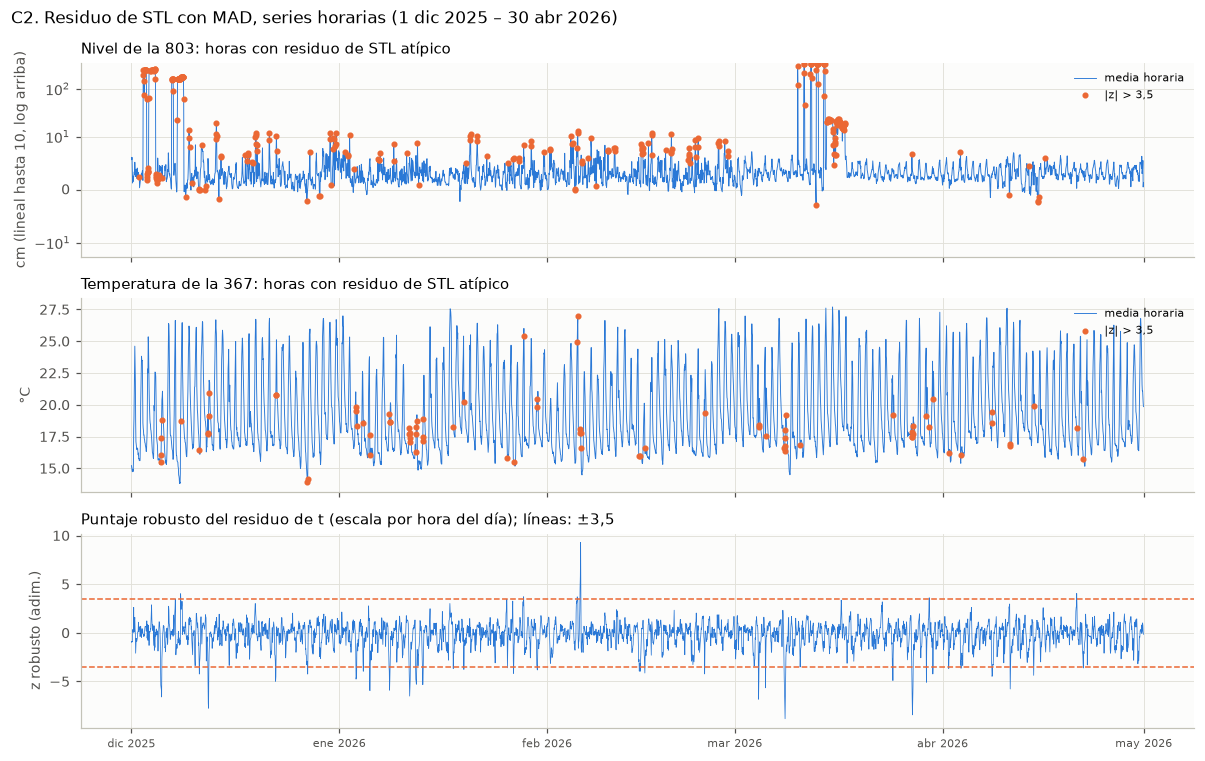

In [8]:
fig, axs = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, c, unidad, titulo in [(axs[0], "803_nivel", "cm", "Nivel de la 803"),
                              (axs[1], "367_t", "°C", "Temperatura de la 367")]:
    r = STL_RES[c]
    ax.plot(r.index, r["valor"], color=AZUL, lw=0.6, label="media horaria")
    ax.scatter(r.index[r["anomalia"]], r["valor"][r["anomalia"]], s=9, color=NARANJA, zorder=3, label="|z| > 3,5")
    ax.set_ylabel(unidad); ax.set_title(f"{titulo}: horas con residuo de STL atípico", loc="left")
    ax.legend(fontsize=7, loc="upper right")
axs[0].set_yscale("symlog", linthresh=10)
axs[0].set_ylabel("cm (lineal hasta 10, log arriba)")
z = STL_RES["367_t"]["z"]
axs[2].plot(z.index, z, color=AZUL, lw=0.5)
axs[2].axhline(3.5, color=NARANJA, ls="--", lw=1); axs[2].axhline(-3.5, color=NARANJA, ls="--", lw=1)
axs[2].set_ylabel("z robusto (adim.)")
axs[2].set_title("Puntaje robusto del residuo de t (escala por hora del día); líneas: ±3,5", loc="left")
eje_fechas(axs[2])
fig.suptitle(f"C2. Residuo de STL con MAD, series horarias ({PERIODO})", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
guardar(fig, "c2_stl")

In [9]:
# Isolation Forest: la contaminación es un supuesto, se muestra cuánto cambia el resultado
ETIQ = {c: A.etiqueta_debil(M[c]["calidad"]) for c in M}
etiq_h = {c: ETIQ[c].resample("h").max() for c in M}
H367 = HORARIA[["367_t", "367_h", "367_pr", "367_vv"]].rename(columns=lambda c: c[4:])
sens = []
for cont in (0.005, 0.01, 0.02):
    r = A.isolation_forest(H367, contaminacion=cont)
    a = r["anomalia"]
    sens.append({"contaminacion": cont, "horas_marcadas": int(a.sum()),
                 "pct_con_lluvia_en_35": 100 * (a & (lluvia_cerca.reindex(a.index) >= 1)).sum() / a.sum(),
                 "precision_vs_etiqueta": (a & etiq_h["367"].reindex(a.index, fill_value=False)).sum() / a.sum(),
                 "hora_mediana": float(np.median(a[a].index.hour))})
print(pd.DataFrame(sens).round(3).to_string(index=False))
IF = A.isolation_forest(H367, contaminacion=0.01)  # 1 %: unas 36 horas, un orden de magnitud manejable para revisar
print("\nHoras marcadas con más puntaje:")
print(IF[IF["anomalia"]].sort_values("puntaje", ascending=False).head(8)
      .join(H367).join(LLUVIA_H.rename("lluvia_35_mm")).round(2).to_string())

 contaminacion  horas_marcadas  pct_con_lluvia_en_35  precision_vs_etiqueta  hora_mediana
         0.005              19                94.737                  0.158          15.0
         0.010              37                75.676                  0.108          15.0
         0.020              73                50.685                  0.082          15.0



Horas marcadas con más puntaje:
                     puntaje  anomalia      t      h      pr    vv  lluvia_35_mm
fecha_hora                                                                      
2026-04-03 16:00:00     0.70      True  15.56  96.13  814.05  2.67         45.72
2026-03-05 14:00:00     0.69      True  17.52  95.58  814.26  2.64         19.30
2026-03-09 15:00:00     0.67      True  19.13  81.07  813.34  2.54         20.57
2026-01-28 15:00:00     0.67      True  18.26  88.52  815.32  1.76         12.19
2025-12-18 15:00:00     0.66      True  18.83  83.55  812.98  2.59         18.29
2026-03-17 17:00:00     0.65      True  18.25  83.16  813.74  2.88          8.64
2026-03-10 17:00:00     0.64      True  17.26  92.92  815.22  1.07          4.06
2026-03-19 19:00:00     0.63      True  18.58  87.90  816.25  1.76         14.73


Contaminación del Isolation Forest: es la fracción de horas que el modelo debe marcar y no se aprende de los datos. En la tabla de arriba, al subir la contaminación baja la fracción de horas marcadas con lluvia en la 35 y baja la precisión frente a la etiqueta: el modelo empieza a marcar horas comunes. Se usa 1 % (unas 37 horas en el periodo), un volumen que una persona puede revisar en un turno. Variables: t, h, pr y vv horarias de la 367, sus cambios en una hora, y seno y coseno de la hora del día; no entran la lluvia (para poder usarla como evidencia externa) ni la dirección (es circular). Escala: mediana y rango intercuartílico.

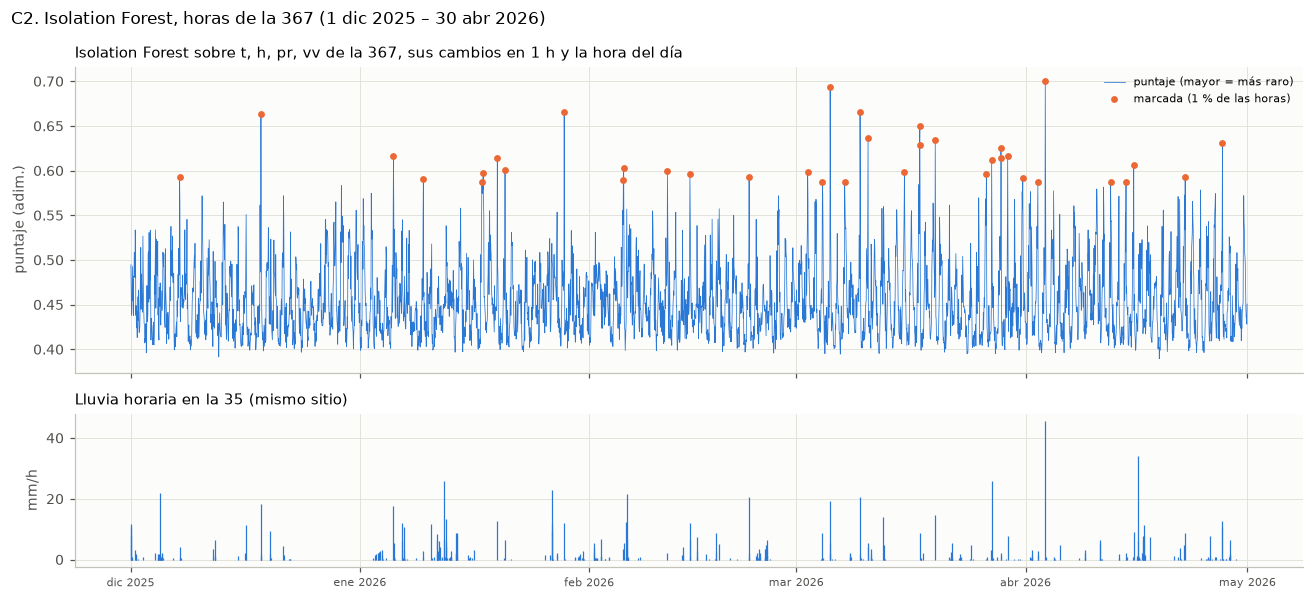

In [10]:
fig, axs = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axs[0].plot(IF.index, IF["puntaje"], color=AZUL, lw=0.5, label="puntaje (mayor = más raro)")
a = IF["anomalia"]
axs[0].scatter(IF.index[a], IF["puntaje"][a], s=12, color=NARANJA, zorder=3, label="marcada (1 % de las horas)")
axs[0].set_ylabel("puntaje (adim.)"); axs[0].legend(fontsize=7, loc="upper right")
axs[0].set_title("Isolation Forest sobre t, h, pr, vv de la 367, sus cambios en 1 h y la hora del día", loc="left")
axs[1].vlines(LLUVIA_H.index, 0, LLUVIA_H.fillna(0), color=AZUL, lw=0.8)
axs[1].set_ylabel("mm/h"); axs[1].set_title("Lluvia horaria en la 35 (mismo sitio)", loc="left")
eje_fechas(axs[1])
fig.suptitle(f"C2. Isolation Forest, horas de la 367 ({PERIODO})", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
guardar(fig, "c2_isolation_forest")

In [11]:
# Cambios de régimen con segmentación binaria
base_803 = m803["nivel"].where(m803["b_nivel"] == Q.BUENO).resample("D").quantile(0.10)  # línea base sin mesetas
dias = pd.DataFrame({"p367": m367["p"].resample("D").sum(min_count=1300),
                     "p35": M["35"][["p1", "p2"]].mean(axis=1).resample("D").sum(min_count=1300)})
razon = (dias["p367"] / dias["p35"]).where(dias["p35"] >= 2)  # días con al menos 2 mm en la 35
kt = (m6004["radiacion"] / EXTRA).where(SOL["elevacion"] > 30)
kt95 = kt.resample("D").quantile(0.95)  # cielo casi despejado: debería ser estable si no hay deriva
# ruido del nivel: escala robusta (1,4826 · MAD) de los cambios de 1 min, solo en minutos secos y con bandera buena
d803 = m803["nivel"].diff().where(m803.index.to_series().diff() == pd.Timedelta("1min"))
ruido_803 = d803.where((lluvia_3h < 0.1) & (m803["b_nivel"] == Q.BUENO)).resample("D").apply(
    lambda x: 1.4826 * (x - x.median()).abs().median() if x.count() > 300 else np.nan)
SEG = {"803 línea base (p10 diario, cm)": A.segmentacion_binaria(base_803),
       "803 ruido (MAD de los cambios de 1 min, cm)": A.segmentacion_binaria(ruido_803),
       "razón diaria de lluvia 367/35": A.segmentacion_binaria(razon, tam_min=5),
       "6004 índice de claridad p95 diario": A.segmentacion_binaria(kt95)}
for nombre, seg in SEG.items():
    print(nombre); print(seg.round({"media": 3}).to_string(index=False)); print()
lluvia_seg = [LLUVIA35.loc[r.inicio:r.fin + pd.Timedelta("1D")].sum() / r.n for r in SEG["803 línea base (p10 diario, cm)"].itertuples()]
print("lluvia media diaria en la 35 por segmento de la línea base (mm/día):", np.round(lluvia_seg, 1))
seg_h = A.segmentacion_binaria(HORARIA["803_nivel"], tam_min=3)
altos = seg_h[seg_h["media"] > Q.UMBRALES["rango_clima"]["nivel"][1]]
meseta_h = F.loc[(F.codigo == "803") & (F.prueba == "rango_clima"), "fecha_hora"].dt.floor("h").unique()
cubiertas = sum(((meseta_h >= r.inicio) & (meseta_h <= r.fin)).sum() for r in altos.itertuples())
print(f"nivel horario: {len(seg_h)} segmentos; {len(altos)} con media > 100 cm, que cubren {cubiertas} de "
      f"{len(meseta_h)} horas con la regla de rango (mesetas)")

803 línea base (p10 diario, cm)
    inicio        fin  n  media
2025-12-01 2026-02-18 80  0.358
2026-02-19 2026-03-02 12 -0.125
2026-03-03 2026-03-15 13  1.289
2026-03-16 2026-04-07 23  1.791
2026-04-08 2026-04-15  8 -0.264
2026-04-16 2026-04-30 15  1.619

803 ruido (MAD de los cambios de 1 min, cm)
    inicio        fin  n  media
2025-12-01 2026-02-04 64  0.445
2026-02-05 2026-03-02 26  0.599
2026-03-03 2026-04-30 59  0.241

razón diaria de lluvia 367/35
    inicio        fin  n  media
2025-12-01 2026-04-28 69  0.352

6004 índice de claridad p95 diario
    inicio        fin   n  media
2025-12-01 2026-04-30 150  0.833

lluvia media diaria en la 35 por segmento de la línea base (mm/día): [ 7.7  4.9  7.8  6.8  4.3 10.5]
nivel horario: 308 segmentos; 22 con media > 100 cm, que cubren 90 de 94 horas con la regla de rango (mesetas)


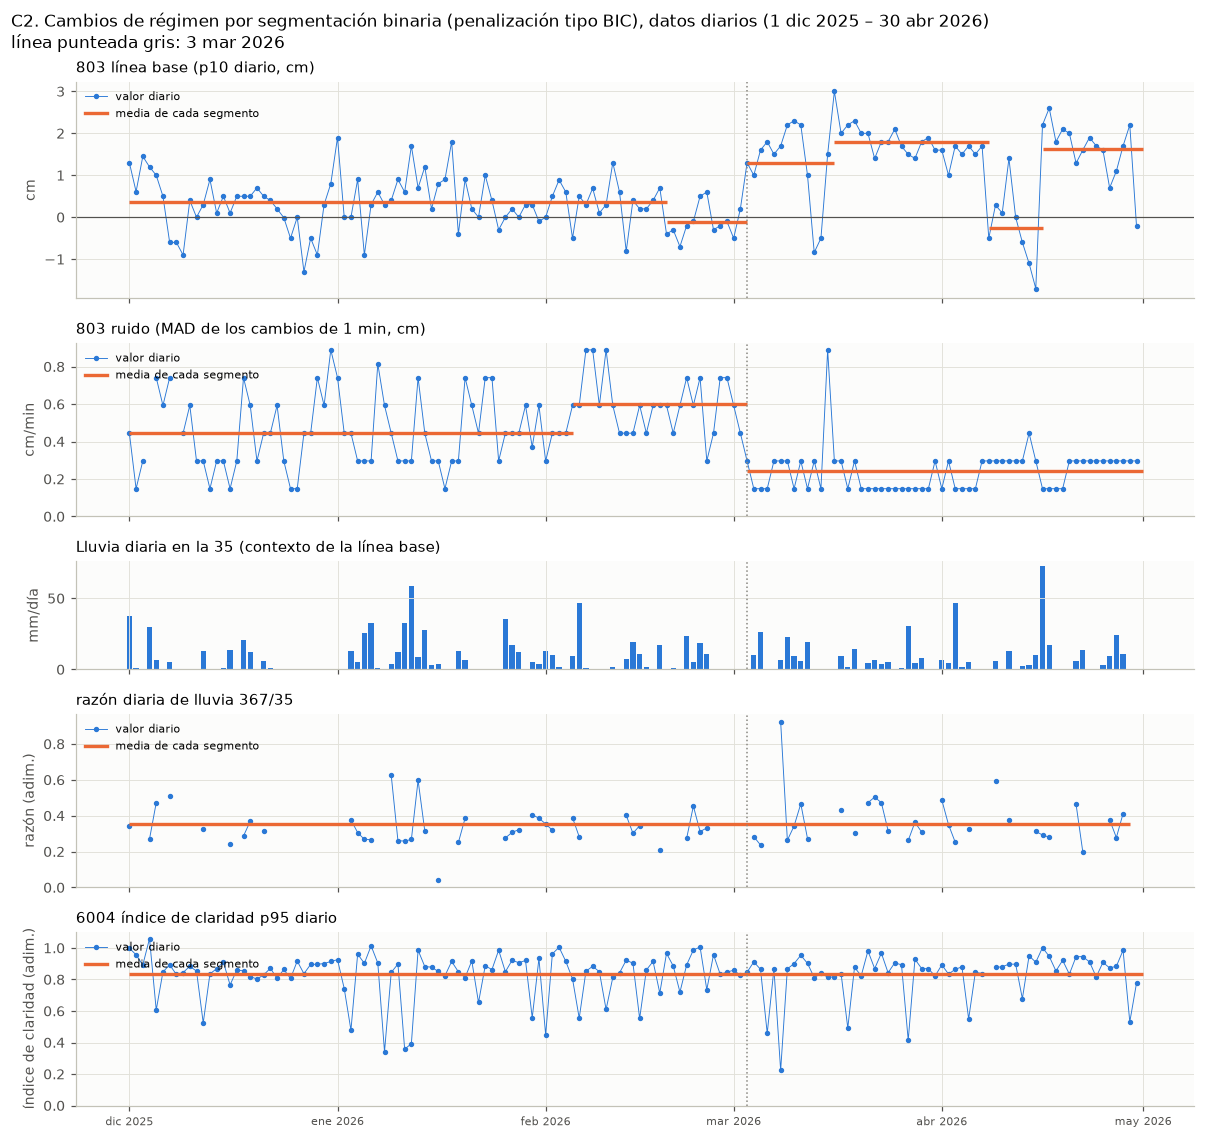

In [12]:
fig, axs = plt.subplots(5, 1, figsize=(11, 10.5), sharex=True, gridspec_kw={"height_ratios": [2, 1.6, 1, 1.6, 1.6]})
filas_fig = [(axs[0], "803 línea base (p10 diario, cm)", base_803, "cm"),
             (axs[1], "803 ruido (MAD de los cambios de 1 min, cm)", ruido_803, "cm/min"),
             (axs[3], "razón diaria de lluvia 367/35", razon, "razón (adim.)"),
             (axs[4], "6004 índice de claridad p95 diario", kt95, "índice de claridad (adim.)")]
for ax, nombre, serie, unidad in filas_fig:
    ax.plot(serie.index, serie, "o-", ms=2.5, lw=0.6, color=AZUL, label="valor diario")
    for r in SEG[nombre].itertuples():
        ax.hlines(r.media, r.inicio, r.fin + pd.Timedelta("1D"), color=NARANJA, lw=2.2)
    ax.plot([], [], color=NARANJA, lw=2.2, label="media de cada segmento")
    ax.set_ylabel(unidad); ax.set_title(nombre, loc="left"); ax.legend(fontsize=7, loc="upper left")
diaria = LLUVIA35.resample("D").sum()
axs[2].bar(diaria.index, diaria, width=0.8, color=AZUL)
axs[2].set_ylabel("mm/día"); axs[2].set_title("Lluvia diaria en la 35 (contexto de la línea base)", loc="left")
axs[0].axhline(0, color=TINTA2, lw=0.8)
for ax in axs[1:]:
    ax.set_ylim(0, None)
for ax in axs:
    ax.axvline(pd.Timestamp("2026-03-03"), color=GRIS, ls=":", lw=1)
eje_fechas(axs[4])
fig.suptitle(f"C2. Cambios de régimen por segmentación binaria (penalización tipo BIC), datos diarios ({PERIODO})\n"
             "línea punteada gris: 3 mar 2026",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
guardar(fig, "c2_cambios_regimen")

### Lectura de C2

- STL marca el 2,2 % de las horas en t (80), el 3,0 % en h (108), el 2,2 % en pr (79), el 8,1 % en el nivel (293) y 2 horas en la radiación. En t, el 60 % de las horas marcadas tiene lluvia en la 35 en esa hora o las dos anteriores, frente al 11,9 % de todas las horas: STL encuentra sobre todo aguaceros. En el nivel solo el 7,5 % tiene lluvia: marca las mesetas y su "sombra" (horas vecinas con residuo enorme porque la tendencia sigue a la meseta, ver C4). En la radiación, la escala robusta del residuo de día va de 108 a 259 W/m² entre las 9 y las 16 h: con tanta nubosidad casi nada sale de 3,5 MAD, y para la 6004 sirve más el límite físico (BSRN) que un residuo estadístico.
- El Isolation Forest marca 37 horas (1 %) y el 76 % tiene lluvia. La más rara es el 3 abr 2026 a las 16 h (45,7 mm en la 35 en esa hora). Detecta tiempo raro más que datos malos.
- Segmentación binaria: en la 803 la línea base y el ruido cambian el mismo día, el 3 mar 2026 (base de -0,12 a 1,29 cm; ruido, medido como MAD de los cambios de 1 min en tiempo seco, de 0,60 a 0,24 cm). Las dos bajadas de la base (19 feb y 8 abr) caen en tramos más secos (4,9 y 4,3 mm/día frente a 6,8 a 10,5 en los demás), así que vienen del caudal base. La razón de lluvia 367/35 es un solo segmento (media de la razón diaria, en días con 2 mm o más en la 35: 0,35): el factor no cambia en el tiempo, lo que descarta un embudo que se tapa poco a poco (que la razón dependa de la intensidad se ve en el notebook 05). El índice de claridad p95 de la 6004 también es un solo segmento (0,83): no hay deriva del piranómetro.
- Sobre el nivel horario, la segmentación encuentra sin umbral fijo 22 segmentos con media sobre 100 cm, que cubren 90 de las 94 horas de meseta de la regla.

## C3. Comparación entre enfoques y contra la columna calidad

La columna `calidad` se usa como etiqueta débil: dudoso = código distinto de 1 y 2 (2 es dato válido que no llegó en tiempo real). No es verdad absoluta: SIATA no publica su algoritmo ni su versión, el algoritmo cambió en el periodo (C4) y hay casos donde la etiqueta se equivoca. Precisión = de lo que marca el enfoque, qué fracción también marca SIATA; exhaustividad = de lo que marca SIATA, qué fracción encuentra el enfoque.

Se evalúa en minutos con dato y con código (las reglas trabajan por minuto) y en horas (todos los enfoques): una hora está marcada si algún minuto lo está. Referencia: un detector al azar tendría precisión igual a la prevalencia de la etiqueta.

In [13]:
REGLAS_MIN = {c: M[c]["b_registro"].isin([Q.SOSPECHOSO, Q.MALO]) for c in M}
EVAL_MIN = {c: M[c]["calidad"].notna() & (M[c]["b_registro"] != Q.FALTANTE) for c in M}
STL_POR_ESTACION = {"367": ["367_t", "367_h", "367_pr"], "803": ["803_nivel"], "6004": ["6004_radiacion"]}

ENFOQUES_H = {}  # codigo -> DataFrame horario con una columna booleana por enfoque
filas = []
for c in M:
    ev = EVAL_MIN[c]
    filas.append({"enfoque": "reglas", "codigo": c, "nivel": "minuto",
                  **A.precision_exhaustividad(REGLAS_MIN[c][ev], ETIQ[c][ev])})
    horas_ev = ev.resample("h").max()
    h = pd.DataFrame({"etiqueta": (ETIQ[c] & ev).resample("h").max(),
                      "reglas": (REGLAS_MIN[c] & ev).resample("h").max()})
    if c in STL_POR_ESTACION:
        h["stl_mad"] = pd.concat([STL_RES[s]["anomalia"] for s in STL_POR_ESTACION[c]], axis=1).any(axis=1) \
            .reindex(h.index, fill_value=False)
    if c == "367":
        h["isolation_forest"] = IF["anomalia"].reindex(h.index, fill_value=False)
    h = h[horas_ev].astype(bool)
    ENFOQUES_H[c] = h
    for enfoque in h.columns.drop("etiqueta"):
        filas.append({"enfoque": enfoque, "codigo": c, "nivel": "hora",
                      **A.precision_exhaustividad(h[enfoque], h["etiqueta"])})
COMPARACION = pd.DataFrame(filas)
COMPARACION["prevalencia"] = COMPARACION["n_etiqueta"] / COMPARACION["n_total"]
print(COMPARACION.round(4).to_string(index=False))
COMPARACION.drop(columns="prevalencia").to_csv(DIR_RES / "comparacion_enfoques.csv", index=False, float_format="%.4f")

         enfoque codigo  nivel  precision  exhaustividad  n_marcados  n_etiqueta  n_total  prevalencia
          reglas    367 minuto     0.0327         0.2657        5567         685   217397       0.0032
          reglas    367   hora     0.0948         0.2129         348         155     3624       0.0428
         stl_mad    367   hora     0.0609         0.0774         197         155     3624       0.0428
isolation_forest    367   hora     0.1081         0.0258          37         155     3624       0.0428
          reglas    803 minuto     0.9978         0.2938        7724       26234   217318       0.1207
          reglas    803   hora     0.9939         0.0747         164        2183     3624       0.6024
         stl_mad    803   hora     0.8464         0.1136         293        2183     3624       0.6024
          reglas   6004 minuto     0.1892         0.0040          37        1730   214823       0.0081
          reglas   6004   hora     0.4000         0.0161          15     

In [14]:
# Kappa del periodo entre la etiqueta y la bandera del registro (lo calcula el pipeline, indicadores_periodo.csv).
# kappa_max: el más alto posible con esas dos prevalencias; kappa / kappa_max separa desacuerdo de distinta sensibilidad
KAPPA = (pd.read_csv(DIR_RES / "indicadores_periodo.csv", dtype={"codigo": str}).drop_duplicates("codigo")
         [["codigo", "kappa", "kappa_max", "falsos_confiables", "dudosos_que_pasan"]])
KAPPA["kappa_sobre_max"] = KAPPA["kappa"] / KAPPA["kappa_max"]
# Sensibilidad: del control propio solo cuenta lo malo (bandera 4); el resto se toma como bueno
solo_malo = {c: confiabilidad_bandera(M[c]["calidad"], M[c]["b_registro"].where(
    M[c]["b_registro"].isin([Q.MALO, Q.FALTANTE]), Q.BUENO), freq=None)["kappa"].iloc[0] for c in ESTACIONES}
KAPPA["kappa_solo_malo"] = KAPPA["codigo"].map(solo_malo)
print(KAPPA.round(3).to_string(index=False))

codigo  kappa  kappa_max  falsos_confiables  dudosos_que_pasan  kappa_sobre_max  kappa_solo_malo
   367  0.053      0.215              0.025              0.734            0.246            0.126
   803  0.419      0.431              0.001              0.706            0.973            0.280
  6004  0.008      0.042              0.000              0.996            0.183            0.000
    35  0.068      0.580              0.001              0.881            0.118            0.000


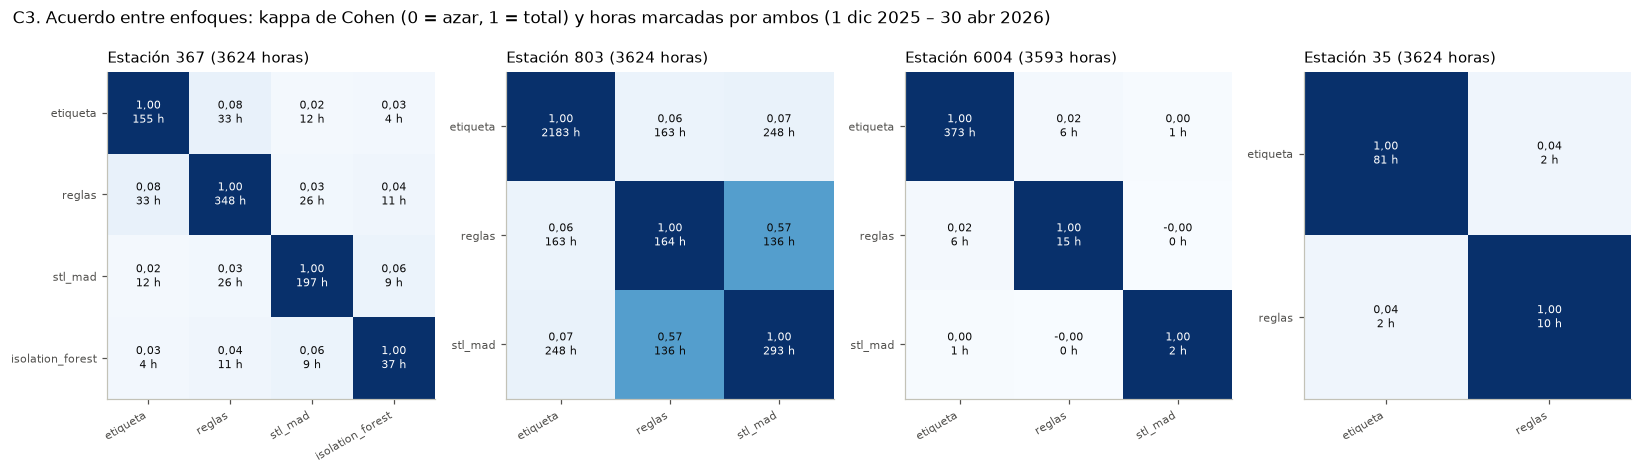

367
                  etiqueta  reglas  stl_mad  isolation_forest
etiqueta             1.000   0.077    0.021             0.026
reglas               0.077   1.000    0.028             0.039
stl_mad              0.021   0.028    1.000             0.061
isolation_forest     0.026   0.039    0.061             1.000
                  etiqueta  reglas  stl_mad  isolation_forest
etiqueta               155      33       12                 4
reglas                  33     348       26                11
stl_mad                 12      26      197                 9
isolation_forest         4      11        9                37

803
          etiqueta  reglas  stl_mad
etiqueta     1.000    0.06    0.067
reglas       0.060    1.00    0.570
stl_mad      0.067    0.57    1.000
          etiqueta  reglas  stl_mad
etiqueta      2183     163      248
reglas         163     164      136
stl_mad        248     136      293

6004
          etiqueta  reglas  stl_mad
etiqueta     1.000   0.023    0.004
regla

In [15]:
# Matriz de acuerdo (kappa de Cohen) entre enfoques, por estación y en horas
fig, axs = plt.subplots(1, 4, figsize=(15, 4.2))
ACUERDO = {}
for ax, (c, h) in zip(axs, ENFOQUES_H.items()):
    cols = list(h.columns)
    k = pd.DataFrame([[kappa(h[a], h[b]) for b in cols] for a in cols], index=cols, columns=cols)
    ambos = pd.DataFrame([[int((h[a] & h[b]).sum()) for b in cols] for a in cols], index=cols, columns=cols)
    ACUERDO[c] = (k, ambos)
    ax.imshow(k.fillna(0).to_numpy(), vmin=0, vmax=1, cmap="Blues")
    for i in range(len(cols)):
        for j in range(len(cols)):
            valor = k.iat[i, j]
            texto = "s. d." if np.isnan(valor) else f"{valor:.2f}".replace(".", ",")
            ax.text(j, i, f"{texto}\n{ambos.iat[i, j]} h", ha="center", va="center", fontsize=7.5,
                    color="white" if (not np.isnan(valor) and valor > 0.6) else TINTA)
    ax.set_xticks(range(len(cols)), cols, rotation=30, ha="right", fontsize=7.5)
    ax.set_yticks(range(len(cols)), cols, fontsize=7.5)
    ax.grid(False)
    ax.set_title(f"Estación {c} ({len(h)} horas)", loc="left")
fig.suptitle(f"C3. Acuerdo entre enfoques: kappa de Cohen (0 = azar, 1 = total) y horas marcadas por ambos ({PERIODO})",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
guardar(fig, "c3_acuerdo")
for c, (k, ambos) in ACUERDO.items():
    print(c); print(k.round(3).to_string()); print(ambos.to_string()); print()

### Lectura de C3

- 803: casi todo lo que marcan las reglas también lo marca SIATA (precisión 0,998 por minuto), pero las reglas encuentran el 29 % de lo que marca SIATA: SIATA marca además el ruido de 1 a 2 cm (1502) y los negativos de diciembre (1504). El kappa del periodo es 0,419 con un máximo posible de 0,431 (el 97 % del máximo): no se contradicen, SIATA es más sensible. Por hora, la etiqueta cubre el 60 % de las horas (basta un minuto con 1502), así que la exhaustividad horaria de cualquier enfoque queda baja por construcción.
- 367, 6004 y 35: kappa de 0,053, 0,008 y 0,068 frente a máximos de 0,215, 0,042 y 0,58. En la 35 el desacuerdo es real (kappa muy por debajo de su máximo): SIATA compara los balancines minuto a minuto y las reglas, en la hora. En la 367 y la 6004 las dos fuentes miran cosas distintas: persistencias, lluvia sin respaldo por hora y saltos de presión frente a la lluvia mínima minuto a minuto (1511) en la 367, donde solo el viento en cero coincide en buena parte (las reglas marcan 50 de los 72 minutos con 1567); crepúsculo (1582) frente a nubes en la 6004.
- Sensibilidad (columna `kappa_solo_malo`): si del control propio solo cuenta lo malo (bandera 4), el kappa de la 367 sube de 0,05 a 0,13, porque lo malo de la 367 es el viento en cero, que SIATA también marca; el de la 803 baja de 0,42 a 0,28, y en la 6004 y la 35 queda en 0 porque sus reglas no marcan nada como malo.
- Referencia ingenua: un detector al azar tendría precisión igual a la prevalencia de la etiqueta. En las horas de la 367 la prevalencia es 0,043 y las reglas, STL y el Isolation Forest logran 0,095, 0,061 y 0,108: apenas por encima del azar. No es que los métodos fallen; la etiqueta de la 367 marca sobre todo otra cosa (lluvia mínima sin respaldo, 1511).
- Entre enfoques, el único acuerdo claro es reglas con STL en el nivel de la 803 (kappa 0,57, 136 horas en común): las mesetas. En lo demás el kappa entre enfoques está entre 0,00 y 0,06: cada método ve un tipo distinto de anomalía, y por eso conviene combinarlos y no elegir uno.

### Casos de desacuerdo, uno por uno

Para cada caso: quién marca, cuántos minutos y la evidencia en los datos. La lectura dice quién tiene la razón según esa evidencia, sin dar por buena ninguna de las dos fuentes.

In [16]:
c367, c803, c6004, c35 = (M[c]["calidad"] for c in ("367", "803", "6004", "35"))
casos = []

# 1) 1582 en el amanecer y el atardecer (6004)
x = m6004[c6004 == 1582]
minuto_dia = m6004.index.hour * 60 + m6004.index.minute
con_luz = m6004["radiacion"] > 0
pct_18 = 100 * ((c6004 == 1582) & con_luz & (m6004.index.hour == 18)).sum() / (con_luz & (m6004.index.hour == 18)).sum()
pct_17 = 100 * ((c6004 == 1582) & con_luz & (m6004.index.hour == 17)).sum() / (con_luz & (m6004.index.hour == 17)).sum()
hm = x.index.hour * 60 + x.index.minute
casos.append({"caso": "1582 en el amanecer y el atardecer", "estacion": "6004", "marca": "SIATA, no las reglas",
              "minutos": len(x),
              "evidencia": f"{100 * (SOL.loc[x.index, 'elevacion'] > 0).mean():.0f} % con el sol sobre el horizonte "
                           f"(elevación mediana {SOL.loc[x.index, 'elevacion'].median():.2f}°); todos entre "
                           f"{hm[hm < 720].min() // 60:02d}:{hm[hm < 720].min() % 60:02d} y "
                           f"{hm[hm < 720].max() // 60:02d}:{hm[hm < 720].max() % 60:02d} o entre "
                           f"{hm[hm >= 720].min() // 60:02d}:{hm[hm >= 720].min() % 60:02d} y "
                           f"{hm[hm >= 720].max() // 60:02d}:{hm[hm >= 720].max() % 60:02d}; marca el {pct_18:.0f} % "
                           f"de los minutos con luz de 18 a 19 h y el {pct_17:.0f} % de 17 a 18 h",
              "lectura": "SIATA usa una ventana de noche fija de reloj (18:00 a 06:00, inferido) y marca el "
                         "crepúsculo real. Las reglas usan la elevación solar."})

# 2) 1583 y radiación sobre la extraterrestre (6004)
sobre = m6004["radiacion"] > EXTRA
grupo_s = (sobre != sobre.shift()).cumsum()
dur_s = sobre.groupby(grupo_s).sum()
dur_s = dur_s[dur_s > 0]
casos.append({"caso": "1583 y realce por nubes", "estacion": "6004",
              "marca": f"SIATA; las reglas, {int(REGLAS_MIN['6004'][sobre].sum())} de esos minutos",
              "minutos": int((c6004 == 1583).sum()),
              "evidencia": f"{int(sobre.sum())} min sobre la extraterrestre horizontal ("
                           f"{int((sobre & (SOL['elevacion'] > 0)).sum())} con el sol arriba y "
                           f"{int((sobre & (SOL['elevacion'] <= 0)).sum())} con el sol bajo el horizonte), de ellos "
                           f"{int((sobre & (c6004 == 1583)).sum())} con 1583, {int((sobre & (c6004 == 1582)).sum())} con 1582 "
                           f"y {int((sobre & (c6004 == 1)).sum())} con 1; razón medida/extraterrestre mediana "
                           f"en 1583: {(m6004['radiacion'] / EXTRA)[c6004 == 1583].median():.2f}; episodios sobre la "
                           f"extraterrestre: mediana {dur_s.median():.0f} min, máximo {dur_s.max()} min; BSRN: "
                           f"{int((F.prueba == 'radiacion_extrema').sum())} min extremadamente raros y 0 imposibles",
              "lectura": "Con el sol arriba, episodios de minutos son realce por nubes (evento real); con el sol "
                         "bajo el horizonte es luz de crepúsculo, donde la extraterrestre vale 0. SIATA compara con otra "
                         "'radiación teórica' no publicada y es inconsistente: deja con 1 el "
                         f"{100 * (sobre & (c6004 == 1)).sum() / sobre.sum():.0f} % de los minutos sobre la extraterrestre."})

# 3) 1502, picos pequeños en el nivel (803)
desvio = (m803["nivel"] - m803["nivel"].rolling(11, center=True, min_periods=6).median()).abs()
casos.append({"caso": "1502, picos pequeños del nivel", "estacion": "803", "marca": "SIATA, no las reglas",
              "minutos": int((c803 == 1502).sum()),
              "evidencia": f"desvío frente a la mediana móvil de 11 min: mediana {desvio[c803 == 1502].median():.1f} cm "
                           f"en 1502 frente a {desvio[c803 == 1].median():.1f} cm con 1; las reglas marcan el "
                           f"{100 * REGLAS_MIN['803'][c803 == 1502].mean():.1f} % de esos minutos (el salto exige 20 cm)",
              "lectura": "Es ruido de 1 a 2 cm, por debajo del umbral de salto. La etiqueta tiene sentido como "
                         "filtro de ruido; para alertas no cambia nada."})

# 4) Niveles negativos: 1504 solo en diciembre (803)
neg = m803["nivel"] < 0
tab_neg = pd.crosstab(neg[neg].index.month, c803[neg])
casos.append({"caso": "Nivel negativo: 1504 solo en diciembre", "estacion": "803", "marca": "SIATA en dic; reglas no",
              "minutos": int(neg.sum()),
              "evidencia": f"diciembre: {int(((c803 == 1504) & neg).sum())} min negativos con 1504 y "
                           f"{int(((c803 == 1) & neg & (m803.index.month == 12)).sum())} con 1; enero a abril: "
                           f"{int(((c803 == 1504) & (m803.index.month != 12)).sum())} con 1504 y "
                           f"{int(((c803 == 1) & neg & (m803.index.month != 12)).sum())} con 1",
              "lectura": "El algoritmo de SIATA cambió en el periodo. Las reglas no marcan negativos a propósito: "
                         "son caudal base bajo un cero mal referido (configuración)."})

# 5) 1511 en la 367: lluvia mínima sin respaldo
p001 = m367["p"].round(3) == 0.01
sin35 = (M["35"]["p1"].fillna(0) == 0) & (M["35"]["p2"].fillna(0) == 0)
primero_1511 = c367[c367 == 1511].index.min()
sin_respaldo = c367.index.isin(F.loc[(F.codigo == "367") & (F.prueba == "lluvia_sin_respaldo"), "fecha_hora"])
hora_otros = c367.index[(c367 == 1511) & ~sin_respaldo].floor("h")
poca = int((agregar(m367["p"], "p", cobertura_min=0.9).reindex(hora_otros).to_numpy()
            < Q.UMBRALES["p_367_sin_respaldo_mm"]).sum())
con35 = int((agregar(LLUVIA35, "p1", cobertura_min=0.9).reindex(hora_otros).to_numpy() > 0).sum())
casos.append({"caso": "1511, lluvia mínima sin respaldo", "estacion": "367", "marca": "SIATA; las reglas, en parte",
              "minutos": int((c367 == 1511).sum()),
              "evidencia": f"{100 * p001[c367 == 1511].mean():.0f} % con p = 0,01 mm y {100 * sin35[c367 == 1511].mean():.1f} % "
                           f"con p1 = p2 = 0 en la 35; pero hay {int(p001.sum())} min con 0,01 mm y solo "
                           f"{int((p001 & (c367 == 1511)).sum())} tienen 1511; primer 1511: {fecha(primero_1511)}; "
                           f"lluvia_sin_respaldo marca {int((sin_respaldo & (c367 == 1511)).sum())} de los minutos con 1511; "
                           f"de los otros {len(hora_otros)}, {poca} caen en horas con menos de 0,08 mm en la 367 y "
                           f"{con35} en horas con lluvia en la 35",
              "lectura": "La regla de SIATA es razonable pero parcial y empezó en enero. Las reglas propias miran "
                         "la hora: lluvia_sin_respaldo exige 0,08 mm en la hora (una vuelta de la 35) sin lluvia en la "
                         "35, y los 0,01 mm sueltos no llegan a ese umbral."})

# 6) 154, humedad en 100 %
h100 = m367["h"] == 100
lluvia_1h = LLUVIA35.fillna(0).rolling("60min").sum().reindex(m367.index) > 0
casos.append({"caso": "154, humedad en 100 %", "estacion": "367", "marca": "SIATA, no las reglas",
              "minutos": int((c367 == 154).sum()),
              "evidencia": f"{int((c367 == 154).sum())} de {int(h100.sum())} min con h = 100 tienen 154 "
                           f"({fecha(c367[c367 == 154].index.min())} y {fecha(c367[c367 == 154].index.max())}); "
                           f"{100 * lluvia_1h[h100].mean():.0f} % de los minutos con h = 100 tienen lluvia en la 35 "
                           f"en la hora previa",
              "lectura": "La saturación con lluvia o niebla es real. SIATA marca 2 rachas y deja el resto: la "
                         "etiqueta es inconsistente. Las reglas no evalúan persistencia con h >= 95 % (nota de la "
                         "OMM, WMO-No. 488, p. 203): una humedad quieta en 100 % es normal con niebla."})

# 7) Viento: 1567 y la meseta de 13 m/s del 5 mar (367)
ceros = (m367[["vv", "vv_max", "dv", "dv_max"]] == 0).all(axis=1)
meseta = m367.loc["2026-03-05 14:57":"2026-03-05 15:05"]
casos.append({"caso": "1567, viento en cero, y meseta de 13 m/s", "estacion": "367",
              "marca": "los dos marcan los ceros; SIATA, además los vecinos; las reglas, la meseta",
              "minutos": int((c367 == 1567).sum()),
              "evidencia": f"{int((ceros & (c367 == 1567)).sum())} de {int(ceros.sum())} min con las cuatro columnas "
                           f"de viento en 0 tienen 1567; las reglas marcan {int(REGLAS_MIN['367'][c367 == 1567].sum())} "
                           f"de los minutos 1567. Meseta 14:57 a 15:05: vv medio {meseta['vv'].mean():.1f} m/s, "
                           f"calidad {sorted(meseta['calidad'].unique().astype(int).tolist())}, reglas marcan "
                           f"{int(REGLAS_MIN['367'].loc[meseta.index].sum())} de {len(meseta)} min",
              "lectura": "Los dos tienen parte de razón: son fallas del anemómetro (tramos en cero en medio de "
                         "viento, y una meseta de 13 m/s con dirección fija y casi sin ráfaga). SIATA no ve la "
                         "meseta. Las reglas ven los ceros (viento_cuadruple_cero) y la meseta (salto y "
                         f"factor_rafaga), pero no {int(((c367 == 1567) & ~REGLAS_MIN['367']).sum())} minutos "
                         "vecinos con viento normal que SIATA marca con 1567."})

# 8) Persistencias que SIATA no marca (367)
p_min = F[(F.codigo == "367") & (F.prueba == "persistencia")]["fecha_hora"].unique()
casos.append({"caso": "Persistencias que SIATA no marca", "estacion": "367", "marca": "reglas, no SIATA",
              "minutos": len(p_min),
              "evidencia": f"{100 * (c367.loc[p_min] == 1).mean():.1f} % con calidad 1; ningún evento repite un solo "
                           f"valor (mínimo {pers['valores_distintos'].min()} valores distintos); racha más larga con "
                           f"el mismo valor de t: {rachas['t']} min; t y h: {100 * ((pers.hora >= 19) | (pers.hora < 7))[pers.variable.isin(['t', 'h'])].mean():.0f} % de los eventos de noche",
              "lectura": "SIATA tiene la razón en el fondo: son noches estables y vientos flojos, el sensor sigue "
                         "cambiando. La OMM pide marcarlos sospechosos para revisión, no rechazarlos, y así quedan "
                         "(bandera 3). En C4 se clasifican como evento físico real."})

# 9) Saltos de presión (367)
casos.append({"caso": "Saltos de presión al mediodía", "estacion": "367", "marca": "reglas, no SIATA",
              "minutos": int(((F.codigo == "367") & (F.prueba == "salto") & (F.variable == "pr")).sum()),
              "evidencia": f"{len(grandes)} saltos de más de 0,5 hPa en un minuto en {grandes.index.normalize().nunique()} días; "
                           f"{int((grandes < 0).sum())} son caídas y {int(((grandes.index.hour >= 9) & (grandes.index.hour < 15)).sum())} "
                           f"ocurren de 9 a 15 h, cuando la presión media baja de {ciclo_pr.max():.1f} hPa "
                           f"({ciclo_pr.idxmax()} h) a {ciclo_pr.min():.1f} hPa ({ciclo_pr.idxmin()} h); solo "
                           f"{int((recupera >= 0.5).sum())} recuperan la mitad del salto en 5 min; calidad 1 en "
                           f"{100 * (c367.loc[grandes.index] == 1).mean():.0f} %",
              "lectura": f"La bajada del día es real (ciclo diurno), pero un escalón mediano de {abs(grandes.median()):.2f} hPa "
                         f"en un minuto, {abs(grandes.median()) / ritmo:.0f} veces el ritmo medio de esa bajada, no lo es: "
                         "el barómetro baja a saltos (inferido, "
                         "sin causa confirmada). Las reglas lo ven y SIATA no. Impacto bajo: la presión no entra a "
                         "las alertas."})

# 10) p1 distinto de p2 con calidad 1 (35)
f35 = F[(F.codigo == "35") & (F.prueba == "p1_p2_difieren")]["fecha_hora"].unique()
dif_min = (M["35"]["p1"] != M["35"]["p2"]) & M["35"]["p1"].notna()
casos.append({"caso": "p1 distinto de p2 con calidad 1", "estacion": "35", "marca": "reglas, no SIATA",
              "minutos": len(f35),
              "evidencia": f"{100 * (c35.loc[f35] == 1).mean():.0f} % de los minutos marcados por la regla horaria tienen "
                           f"calidad 1; hay {int(dif_min.sum())} minutos con p1 distinto de p2 y SIATA marca "
                           f"{int(c35.isin([1511, 1512, 2512]).sum())} (1511, 1512, 2512)",
              "lectura": "SIATA compara minuto a minuto y deja pasar diferencias acumuladas en la hora. Un "
                         "balancín que se atasca se ve en la hora, no en el minuto."})

# 10b) Dirección 0 con viento (367): la regla de la OMM frente a la convención del registrador
dz = (m367["vv"] > 0) & (m367["dv"] == 0)
casos.append({"caso": "Dirección 0 con viento", "estacion": "367", "marca": "ninguno (convención)",
              "minutos": int(dz.sum()),
              "evidencia": f"calidad 1 en {100 * (c367[dz] == 1).mean():.1f} %; dv es entera y va de "
                           f"{m367['dv'].min():.0f} a {m367['dv'].max():.0f} (nunca 360) mientras dv_max llega a 360 en "
                           f"{int((m367['dv_max'] == 360).sum())} min; minutos con dv = 0, 1 y 359: "
                           f"{int((m367['dv'] == 0).sum())}, {int((m367['dv'] == 1).sum())} y {int((m367['dv'] == 359).sum())}; "
                           f"vv mediana en esos minutos {m367.loc[dz, 'vv'].median():.2f} m/s",
              "lectura": "SIATA tiene la razón: dv usa la escala 0 a 359 y escribe el norte como 0; el 0 es tan "
                         "frecuente como 1 o 359. La regla de la OMM supone la convención 360 = norte, por eso esa mitad "
                         "de la regla no se aplica y estos minutos no se marcan. Es un problema de configuración del "
                         "registrador (dv y dv_max usan convenciones distintas), no del viento."})

# 11) Mesetas del nivel: acuerdo
casos.append({"caso": "Mesetas del nivel (acuerdo)", "estacion": "803", "marca": "los dos",
              "minutos": int(mesetas["minutos"].sum()),
              "evidencia": f"{len(mesetas)} episodios; {mesetas['pct_siata_dudoso'].min():.0f} % a "
                           f"{mesetas['pct_siata_dudoso'].max():.0f} % de los minutos con código dudoso en cada uno",
              "lectura": "Aquí los dos enfoques coinciden: es lo que sube el kappa de la 803."})

# 12) Modelos estadísticos frente a la etiqueta
casos.append({"caso": "Horas raras para STL e Isolation Forest", "estacion": "367 y 803", "marca": "modelos, no SIATA",
              "minutos": np.nan,
              "evidencia": f"Isolation Forest: {sens[1]['pct_con_lluvia_en_35']:.0f} % de las horas marcadas con lluvia "
                           f"en la 35 ({tabla_stl.loc[0, 'pct_horas_con_lluvia_en_35']:.1f} % de todas las horas); "
                           f"STL de t: {tabla_stl.loc[0, 'pct_con_lluvia_en_35']:.0f} %",
              "lectura": "Los modelos encuentran tiempo raro (aguaceros), no datos malos. Su baja precisión "
                         "frente a la etiqueta es esperada y no los descalifica para detectar eventos."})
CASOS = pd.DataFrame(casos)
for i, r in enumerate(CASOS.itertuples(), 1):
    minutos = "" if pd.isna(r.minutos) else f", {int(r.minutos)} min"
    print(f"{i}. {r.caso} (estación {r.estacion}; marca: {r.marca}{minutos})\n   evidencia: {r.evidencia}\n"
          f"   lectura: {r.lectura}\n")

1. 1582 en el amanecer y el atardecer (estación 6004; marca: SIATA, no las reglas, 977 min)
   evidencia: 79 % con el sol sobre el horizonte (elevación mediana 0.86°); todos entre 05:46 y 06:00 o entre 18:00 y 18:20; marca el 100 % de los minutos con luz de 18 a 19 h y el 0 % de 17 a 18 h
   lectura: SIATA usa una ventana de noche fija de reloj (18:00 a 06:00, inferido) y marca el crepúsculo real. Las reglas usan la elevación solar.

2. 1583 y realce por nubes (estación 6004; marca: SIATA; las reglas, 7 de esos minutos, 753 min)
   evidencia: 1162 min sobre la extraterrestre horizontal (612 con el sol arriba y 550 con el sol bajo el horizonte), de ellos 445 con 1583, 244 con 1582 y 473 con 1; razón medida/extraterrestre mediana en 1583: 1.01; episodios sobre la extraterrestre: mediana 2 min, máximo 16 min; BSRN: 5 min extremadamente raros y 0 imposibles
   lectura: Con el sol arriba, episodios de minutos son realce por nubes (evento real); con el sol bajo el horizonte es luz de crepúsc

## C4. Eventos relevantes, clasificados

Un evento es un tramo de minutos contiguos marcados en la misma estación y variable. Se unen las marcas separadas por un minuto o menos; en las reglas que se evalúan por hora (balancines de la 35, lluvia de la 367 frente a la 35) se unen las marcas de horas seguidas. Si varias variables tienen exactamente el mismo tramo (por ejemplo, un hueco de la 367 deja sin dato las ocho columnas), van en una sola fila.

Fuentes de la tabla:
1. Reglas deterministas (traza `fallas.parquet`). La regla de dirección del viento (`direccion_sin_viento`) se resume en una sola fila de configuración de la 367, porque su causa es una convención del registrador (ver C3).
2. STL e Isolation Forest, solo las horas con 1 mm o más de lluvia en la 35 desde 3 h antes: son los extremos reales que hay que mostrar y no borrar. Si el modelo marca un tramo que las reglas ya dan por falla (por ejemplo, alrededor de una meseta del nivel), ese evento ya está en la tabla. Las horas marcadas por un modelo, sin lluvia y sin otra evidencia, no se clasifican (abajo se cuentan): que un modelo diga "hora rara" no basta para llamar falla a un dato.
3. Columna `calidad` de SIATA: código 2 en la 35 (datos que llegaron tarde, que ninguna regla puede ver) y 1567 en la 367 (viento en cero; los minutos con las cuatro columnas en 0 también los marca la regla `viento_cuadruple_cero`).
4. Problemas de configuración de cada estación, encontrados en los EDA (notebooks 01 a 05) y en C2.

Tipo (función `anomalias.tipo_evento`; si hay varias lecturas, gana la de falla): hueco sin centinela = falla de comunicación; hueco con -999 = falla de sensor; convención del registrador (dirección, resolución) = problema de configuración; radiación extrema o salto de radiación = evento físico real (realce y paso de nubes); persistencia con el sensor todavía cambiando = evento físico real (condición estable); salto o modelo con 1 mm o más de lluvia en la 35 = evento físico real; lo demás = falla de sensor. El criterio automático se corrige a mano solo con evidencia escrita en la fila (un caso: la meseta de viento del 5 mar 2026, ver C3).

Severidad (función `anomalias.severidad`), ligada a las alertas de inundación, que usan nivel y lluvia. Problema del dato: alta si toca nivel o lluvia y el dato es malo (bandera 4) o el problema dura una hora o más (la quebrada llega al pico una mediana de 25 min después de empezar a llover, en los 47 eventos del notebook 02, así que una hora sin dato confiable deja pasar una creciente); media si toca nivel o lluvia por menos de una hora, u otra variable por una hora o más; baja si es otra variable por menos de una hora. Evento físico real: alta si es de nivel o lluvia (borrarlo dejaría a la alerta sin el dato que más necesita), baja en otro caso.

In [17]:
LL0 = LLUVIA35.fillna(0)
TRES_H = pd.Timedelta("3h")


def num(x, decimales=1):
    """Número para texto en español: coma decimal y espacio de miles."""
    return f"{x:,.{decimales}f}".replace(",", " ").replace(".", ",")


HORARIAS = {"p1_p2_difieren", "lluvia_no_registrada", "lluvia_sin_respaldo"}
CONVENCION = {"direccion_sin_viento"}  # una fila de configuración, más abajo
f = F[~F["prueba"].isin(CONVENCION | {"sin_contexto"})]  # sin_contexto: no evaluado por falta de lluvia de referencia, no es anomalía
f = f.assign(inicio=f["fecha_hora"], fin=f["fecha_hora"], familia=np.where(f["prueba"] == "hueco", "hueco", "valor"))
cols = ["codigo", "variable", "familia", "inicio", "fin", "prueba", "bandera"]
ER = pd.concat([A.eventos(f.loc[~f["prueba"].isin(HORARIAS), cols], "1min", por=("codigo", "variable", "familia")),
                A.eventos(f.loc[f["prueba"].isin(HORARIAS), cols], "59min", por=("codigo", "variable", "familia"))],
               ignore_index=True)
ER = (ER.groupby(["codigo", "familia", "inicio", "fin", "prueba", "bandera", "duracion_min"], as_index=False)
      ["variable"].agg(lambda v: "+".join(sorted(v))))


def contexto(e):
    x = M[e.codigo].loc[e.inicio:e.fin]
    una = "+" not in e.variable
    return pd.Series({"lluvia_mm": LL0.loc[e.inicio - TRES_H:e.fin].sum(),
                      "valores_distintos": x[e.variable].nunique() if una else np.nan,
                      "centinela": bool(x["centinela"].any()),
                      "pct_siata": 100 * A.etiqueta_debil(x["calidad"]).mean(),
                      "minimo": x[e.variable].min() if una else np.nan,
                      "maximo": x[e.variable].max() if una else np.nan})


ER = ER.join(ER.apply(contexto, axis=1))
ER["tipo"] = [A.tipo_evento(e.prueba, e.variable, e.lluvia_mm,
                            None if pd.isna(e.valores_distintos) else e.valores_distintos, e.centinela)
              for e in ER.itertuples()]
ER["severidad"] = [A.severidad(e.tipo, e.variable, e.duracion_min, e.bandera) for e in ER.itertuples()]


def describir(e):
    partes = [" ".join(Q.DESCRIPCION_PRUEBA[p] for p in e.prueba.split("+"))]
    if e.familia == "valor" and "+" not in e.variable:
        partes.append(f"Valores de {num(e.minimo)} a {num(e.maximo)} {VARIABLES[e.variable]['unidad']}"
                      f" ({int(e.valores_distintos)} distintos).")
    partes.append(f"Lluvia en la 35 desde 3 h antes: {num(e.lluvia_mm)} mm.")
    partes.append(f"SIATA marca dudoso el {num(e.pct_siata, 0)} % de los minutos.")
    return " ".join(partes)


ER = ER.assign(detector="reglas deterministas", regla_o_modelo=ER["prueba"], descripcion=ER.apply(describir, axis=1))

# Revisión manual (C3, caso del viento): la meseta de 13 m/s del 5 mar 2026. El criterio automático la da por real
# porque llovió antes, pero la evidencia apunta al sensor; se corrige aquí y queda la constancia en la tabla.
a, b = pd.Timestamp("2026-03-05 14:56"), pd.Timestamp("2026-03-05 15:06")
meseta_vv = m367.loc[a + pd.Timedelta("1min"):b - pd.Timedelta("1min")]
quitar = (ER["codigo"] == "367") & (ER["variable"] == "vv") & (ER["inicio"] >= a) & (ER["fin"] <= b)
ER = pd.concat([ER[~quitar], pd.DataFrame([{
    "codigo": "367", "variable": "vv", "familia": "valor", "inicio": a, "fin": b, "prueba": "salto", "bandera": Q.SOSPECHOSO,
    "duracion_min": int((b - a) / pd.Timedelta("1min")) + 1, "tipo": "falla de sensor",
    "severidad": A.severidad("falla de sensor", "vv", 11, Q.SOSPECHOSO),
    "detector": "reglas deterministas", "regla_o_modelo": "salto + revisión manual",
    "descripcion": f"Meseta de viento: vv sube de {num(m367.loc[a, 'vv'])} a {num(meseta_vv['vv'].mean())} m/s en un minuto, "
                   f"se queda {len(meseta_vv)} min con dirección fija ({meseta_vv['dv'].min():.0f} a "
                   f"{meseta_vv['dv'].max():.0f}°) y factor de ráfaga {num((meseta_vv['vv_max'] / meseta_vv['vv']).mean(), 2)}, "
                   f"y cae a {num(m367.loc[b, 'vv'])} m/s en un minuto. Un viento real de 13 m/s es racheado; la regla "
                   f"solo marca los bordes y SIATA deja calidad 1. Lluvia en la 35 desde 3 h antes: "
                   f"{num(LL0.loc[a - TRES_H:b].sum())} mm, pero no explica una meseta así (inferido)."}])],
               ignore_index=True)

# Revisión manual del pico del 3 abr 2026: la lluvia es real, pero la forma del pico del nivel no es la de una creciente
n3 = m803["nivel"].loc["2026-04-03 16:27":"2026-04-03 16:32"]
nota = (ER["codigo"] == "803") & (ER["variable"] == "nivel") & (ER["inicio"] == n3.index[-2])
assert nota.sum() == 1, "no está el salto del 3 abr 2026 a las 16:31"
ER.loc[nota, "descripcion"] += (
    f" Revisión manual: el nivel sube de {num(n3.iloc[0])} a {num(n3.iloc[1])} cm en un minuto, se queda "
    f"{len(n3) - 2} min cerca de {num(n3.iloc[1:-1].max(), 0)} cm y cae a {num(n3.iloc[-1])} cm mientras la 35 sigue "
    f"registrando {num(LL0.loc[n3.index[-1]:n3.index[-1] + pd.Timedelta('5min')].mean(), 2)} mm/min. La creciente es real; "
    f"ese bloque de {len(n3) - 2} min puede ser un artefacto de la medición con lluvia intensa (inferido). Queda sospechoso y no se borra.")
print(ER.loc[nota, "descripcion"].iloc[0])
print(len(ER), "eventos de las reglas")
print(pd.crosstab([ER["codigo"], ER["prueba"]], ER["tipo"]).to_string())

Cambio entre minutos consecutivos mayor que el máximo plausible. Valores de 5,9 a 29,0 cm (2 distintos). Lluvia en la 35 desde 3 h antes: 37,3 mm. SIATA marca dudoso el 0 % de los minutos. Revisión manual: el nivel sube de 12,2 a 28,9 cm en un minuto, se queda 4 min cerca de 30 cm y cae a 5,9 cm mientras la 35 sigue registrando 0,59 mm/min. La creciente es real; ese bloque de 4 min puede ser un artefacto de la medición con lluvia intensa (inferido). Queda sospechoso y no se borra.
699 eventos de las reglas
tipo                                        evento físico real  falla de comunicación  falla de sensor
codigo prueba                                                                                         
35     hueco                                                 0                      0                6
       p1_p2_difieren                                        0                      0               16
367    factor_rafaga                                         0              

In [18]:
# Eventos de los modelos: horas marcadas por STL o Isolation Forest, unidas si son seguidas
marcas = [pd.DataFrame({"codigo": s.split("_")[0], "variable": s.split("_", 1)[1], "inicio": r.index[r["anomalia"]],
                        "prueba": "stl_mad"}) for s, r in STL_RES.items()]
marcas.append(pd.DataFrame({"codigo": "367", "variable": "h+pr+t+vv", "inicio": IF.index[IF["anomalia"]],
                            "prueba": "isolation_forest"}))
EM = pd.concat(marcas, ignore_index=True)
EM["fin"] = EM["inicio"] + pd.Timedelta("59min")
EM = A.eventos(EM, "1min")
EM["lluvia_mm"] = [LL0.loc[e.inicio - TRES_H:e.fin].sum() for e in EM.itertuples()]


FALLAS_REGLAS = ER[(ER["familia"] == "valor") & (ER["tipo"] != "evento físico real")]


def coincide_con_falla(e):
    """El modelo marca un tramo que las reglas ya dan por falla: ese evento ya está en la tabla."""
    r = FALLAS_REGLAS[(FALLAS_REGLAS["codigo"] == e.codigo) & (FALLAS_REGLAS["inicio"] <= e.fin)
                      & (FALLAS_REGLAS["fin"] >= e.inicio)]
    return bool(set(e.variable.split("+")) & set("+".join(r["variable"]).split("+")))


EM["con_falla"] = [coincide_con_falla(e) for e in EM.itertuples()]
EM["grupo"] = np.select([EM["con_falla"], EM["lluvia_mm"] >= 1],
                        ["coincide con una falla de las reglas", "con lluvia (a la tabla)"], "seco, sin otra evidencia")
print(pd.crosstab([EM["prueba"], EM["codigo"], EM["variable"]], EM["grupo"]).to_string())
print("\nEjemplo de 'sombra' de STL junto a una meseta del nivel (3 dic 2025): el valor es normal y el residuo enorme,")
print("porque la tendencia sigue a la meseta de unos 245 cm de las horas vecinas")
print(STL_RES["803_nivel"].loc["2025-12-03 08:00":"2025-12-03 12:00"].round(1).to_string())

grupo                              coincide con una falla de las reglas  con lluvia (a la tabla)  seco, sin otra evidencia
prueba           codigo variable                                                                                          
isolation_forest 367    h+pr+t+vv                                     4                       22                         8
stl_mad          367    h                                             0                       23                        25
                        pr                                            7                       13                        25
                        t                                             0                       25                        17
                 6004   radiacion                                     0                        1                         1
                 803    nivel                                        21                       14                        66

Ejemplo de 'som

In [19]:
EMt = EM[EM["grupo"] == "con lluvia (a la tabla)"].copy()
EMt["tipo"] = [A.tipo_evento(e.prueba, e.variable, e.lluvia_mm) for e in EMt.itertuples()]
EMt["severidad"] = [A.severidad(e.tipo, e.variable, e.duracion_min) for e in EMt.itertuples()]
EMt["detector"] = EMt["prueba"].map({"stl_mad": "STL + MAD", "isolation_forest": "Isolation Forest"})
EMt["regla_o_modelo"] = EMt["prueba"]


def describir_modelo(e):
    x = M[e.codigo].loc[e.inicio:e.fin]
    rango = "".join(f" {v}: {num(x[v].min())} a {num(x[v].max())} {VARIABLES[v]['unidad']}."
                    for v in e.variable.split("+"))
    return (f"Hora atípica para {e.detector} con {num(e.lluvia_mm)} mm de lluvia en la 35 desde 3 h antes: la "
            f"variable responde a la lluvia; se reporta y no se borra.{rango}")


EMt["descripcion"] = EMt.apply(describir_modelo, axis=1)


# Eventos de la columna calidad de SIATA: el código 2 no lo ve ninguna regla; el 1567 se contrasta con
# viento_cuadruple_cero (los minutos con las cuatro columnas en 0 los marca malos esa regla)
def eventos_codigo(c, codigo_calidad, variable):
    t = M[c].index[M[c]["calidad"] == codigo_calidad]
    return A.eventos(pd.DataFrame({"codigo": c, "variable": variable, "inicio": t, "fin": t}), "1min")


e2 = eventos_codigo("35", 2, "p1+p2").assign(
    tipo="falla de comunicación", regla_o_modelo="código 2",
    descripcion=lambda d: [f"Código 2 de SIATA: los datos llegaron después, no en tiempo real (definición de las guías de SIATA). En ese tramo la "
                           f"alerta no habría tenido la 35; luego los datos se recuperaron completos. Lluvia del tramo: "
                           f"p1 {num(M['35']['p1'].loc[a:b].sum())} mm y p2 {num(M['35']['p2'].loc[a:b].sum())} mm."
                           for a, b in zip(d["inicio"], d["fin"])])
ceros = (m367[["vv", "vv_max", "dv", "dv_max"]] == 0).all(axis=1)


def describir_1567(a, b):
    pct = 100 * ceros.loc[a:b].mean()
    if pct > 0:
        return (f"Código 1567 de SIATA: vv, vv_max, dv y dv_max en 0 a la vez en el {num(pct, 0)} % de los minutos; "
                f"esos minutos los marca malos la regla viento_cuadruple_cero. vv máxima en los 5 min previos: "
                f"{num(m367['vv'].loc[a - pd.Timedelta('5min'):a - pd.Timedelta('1min')].max())} m/s. Caída a cero "
                f"de la lectura del anemómetro (inferido).")
    x = m367.loc[a:b, "vv"]
    return (f"Código 1567 de SIATA sin ceros: vv entre {num(x.min())} y {num(x.max())} m/s. Son minutos vecinos de los "
            f"ceros del mismo día: SIATA marca el episodio completo y las reglas solo los ceros.")


e1567 = eventos_codigo("367", 1567, "dv+dv_max+vv+vv_max").assign(
    tipo="falla de sensor", regla_o_modelo="código 1567",
    descripcion=lambda d: [describir_1567(a, b) for a, b in zip(d["inicio"], d["fin"])])
EC = pd.concat([e2, e1567], ignore_index=True).assign(detector="columna calidad de SIATA")
EC["severidad"] = [A.severidad(e.tipo, e.variable, e.duracion_min) for e in EC.itertuples()]
print(EC.groupby(["codigo", "regla_o_modelo"]).agg(eventos=("inicio", "size"), minutos=("duracion_min", "sum")))

                       eventos  minutos
codigo regla_o_modelo                  
35     código 2              1     2944
367    código 1567          10       72


### Problemas de configuración de cada estación

No son minutos sueltos sino decisiones de montaje, reloj, escala o del propio control de calidad que afectan todo el periodo o un tramo largo. Cada fila lleva la evidencia calculada aquí.

In [20]:
def periodo(c):
    """Primer y último minuto con dato de la estación (hora local)."""
    con = M[c]["presente"]
    return M[c].index[con.argmax()], M[c].index[len(con) - 1 - con[::-1].argmax()]


# 1) Reloj de la 6004: radiación sobre la extraterrestre si el archivo se lee como hora local o como UTC
crudo = cargar("6004").set_index("fecha_hora")["radiacion"]
crudo = crudo[crudo > -999]
sobre_extra = {}
for lectura, horas in (("hora local", 0), ("UTC", -5)):
    sol = Q.geometria_solar(crudo.index + pd.Timedelta(hours=horas), ESTACIONES["6004"]["lat"], ESTACIONES["6004"]["lon"])
    sobre_extra[lectura] = int((crudo.to_numpy() > (sol["sa"] * sol["cos_z"].clip(lower=0)).to_numpy()).sum())
hora_pico = int(crudo.groupby(crudo.index.hour).mean().idxmax())

# 2) Escala de la lluvia de la 367 frente a la 35 (mismo sitio), días completos
dias_c = pd.DataFrame({"p367": m367["p"].resample("D").sum(min_count=1440),
                       "p1": M["35"]["p1"].resample("D").sum(min_count=1440)}).dropna()
pendiente = (dias_c["p367"] * dias_c["p1"]).sum() / (dias_c["p1"] ** 2).sum()
r_dias = dias_c.corr().iloc[0, 1]

# 3) Cero de referencia de la 803
pct_neg = 100 * (m803["nivel"] < 0).sum() / m803["nivel"].notna().sum()
min_diario = m803["nivel"].resample("D").min().median()


# 4) Cambio del 3 mar 2026 en la 803 (segmentación binaria de C2): cortes más cercanos a esa fecha
def corte_cercano(seg, fecha_ref="2026-03-03"):
    i = int((seg["inicio"].iloc[1:] - pd.Timestamp(fecha_ref)).abs().argmin()) + 1
    return seg["inicio"].iloc[i], seg["media"].iloc[i - 1], seg["media"].iloc[i]


corte_base = corte_cercano(SEG["803 línea base (p10 diario, cm)"])
corte_ruido = corte_cercano(SEG["803 ruido (MAD de los cambios de 1 min, cm)"])
print("corte de la línea base:", corte_base, "| corte del ruido:", corte_ruido)

# 5) Ventana de noche de 1582: minutos de reloj
x1582 = m6004[c6004 == 1582]
minuto_1582 = x1582.index.hour * 60 + x1582.index.minute
pct_ventana = 100 * ((minuto_1582 >= 18 * 60) | (minuto_1582 <= 6 * 60)).mean()  # 18:00 a 06:00, extremos incluidos
pct_sol = 100 * (SOL.loc[x1582.index, "elevacion"] > 0).mean()

# 6) Cambio del algoritmo de calidad de SIATA en el periodo
mes = m803.index.month
neg = m803["nivel"] < 0
alg = {"1504 en dic": int(((c803 == 1504) & (mes == 12)).sum()), "1504 ene-abr": int(((c803 == 1504) & (mes != 12)).sum()),
       "negativos con 1 ene-abr": int((neg & (c803 == 1) & (mes != 12)).sum()),
       "251 fuera de dic": int(((c803 == 251) & (mes != 12)).sum()),
       "2502 en dic (%)": 100 * ((c803 == 2502) & (mes == 12)).sum() / (c803 == 2502).sum(),
       "primer 1511 en la 367": fecha(c367[c367 == 1511].index.min())}
print(alg)

# 7) Convención de la dirección del viento en la 367 (reglas de la OMM que no aplican a este registrador)
n_cero = int(((m367["vv"] > 0) & (m367["dv"] == 0)).sum())  # no se marca: con esta escala 0 es el norte
n_sin = int(((F.codigo == "367") & (F.prueba == "direccion_sin_viento")).sum())

configuracion = [
    ("6004", "radiacion", "revisión de metadatos y EDA", "reloj en UTC",
     f"El archivo de la 6004 está en UTC y las demás en hora local. Leído como hora local, {num(sobre_extra['hora local'], 0)} "
     f"registros superan la radiación extraterrestre; leído como UTC, {num(sobre_extra['UTC'], 0)}. El pico medio cae a las "
     f"{hora_pico} h del archivo (mediodía solar local + 5 h). Se corrige al cargar (resta de 5 h); debe declararse en el "
     f"catálogo."),
    ("367", "p", "revisión de metadatos y EDA", "escala de la lluvia",
     f"La 367 registra {num(pendiente, 3)} veces la lluvia de la 35 en el mismo punto (regresión por el origen en "
     f"{len(dias_c)} días completos, correlación {num(r_dias, 3)}): totales {num(m367['p'].sum())} mm frente a "
     f"{num(M['35']['p1'].sum())} mm (p1). Factor o resolución mal configurados en el registrador, o captación "
     f"deficiente (sin confirmar). No usar la p de la 367 para alertas hasta calibrar."),
    ("803", "nivel", "revisión de metadatos y EDA", "cero de referencia",
     f"El {num(pct_neg)} % de los niveles es negativo y el mínimo diario mediano es {num(min_diario)} cm: el cero está "
     f"sobre el caudal base y no está documentado. Los negativos no se marcan: son agua real bajo un cero mal referido."),
    ("803", "nivel", "segmentación binaria", "cambio de régimen",
     f"Desde el {fecha(corte_base[0])} la línea base pasa de {num(corte_base[1], 2)} a {num(corte_base[2], 2)} cm y desde el "
     f"{fecha(corte_ruido[0])} el ruido (MAD de los cambios de 1 min) pasa de {num(corte_ruido[1], 2)} a "
     f"{num(corte_ruido[2], 2)} cm. Probable intervención no documentada (limpieza, reubicación o cambio del sensor)."),
    ("6004", "radiacion", "columna calidad de SIATA", "código 1582",
     f"El control de SIATA usa una ventana de noche de reloj: el {num(pct_ventana, 0)} % de los {len(x1582)} minutos con "
     f"1582 cae entre las 18:00 y las 06:00 y el {num(pct_sol, 0)} % tiene el sol sobre el horizonte. Marca como dudoso el "
     f"crepúsculo real; debe usar la elevación solar."),
    ("803", "nivel", "columna calidad de SIATA", "cambio del algoritmo de calidad",
     f"El algoritmo de calidad de SIATA cambió durante el periodo sin aviso: 1504 (nivel negativo) en {alg['1504 en dic']} "
     f"minutos de diciembre y {alg['1504 ene-abr']} de enero a abril, cuando {num(alg['negativos con 1 ene-abr'], 0)} "
     f"negativos salen con 1; 251 fuera de diciembre: {alg['251 fuera de dic']}; 2502 en diciembre: "
     f"{num(alg['2502 en dic (%)'], 0)} %. En la 367 el código 1511 aparece desde el {alg['primer 1511 en la 367']}. "
     f"La etiqueta no es comparable entre meses."),
    ("367", "dv", "reglas deterministas", "direccion_sin_viento",
     f"dv usa la escala 0 a 359 (el norte es 0) y dv_max llega a 360. La regla de coherencia de la OMM supone 360 = "
     f"norte y 0 = calma. Hay {n_cero} minutos con viento y dirección 0: con esta escala son viento del norte, así que "
     f"la mitad de la regla que pide dirección distinta de 0 con viento no se aplica. Hay {n_sin} minutos con "
     f"velocidad 0 y dirección distinta de 0 (direccion_sin_viento, sospechoso): la veleta queda donde la dejó el "
     f"último viento. Es una convención del registrador, no viento malo."),
]
filas = []
for c, v, detector, regla, texto in configuracion:
    a, b = periodo(c)
    if regla == "cambio de régimen":
        a = min(corte_base[0], corte_ruido[0])
    dur = int((b - a) / pd.Timedelta("1min")) + 1
    filas.append({"codigo": c, "variable": v, "inicio": a, "fin": b, "duracion_min": dur,
                  "tipo": "problema de configuración", "detector": detector, "regla_o_modelo": regla,
                  "severidad": A.severidad("problema de configuración", v, dur), "descripcion": texto})
ECONF = pd.DataFrame(filas)
for r in ECONF.itertuples():
    print(f"{r.codigo} {r.variable} ({r.severidad}): {r.descripcion}\n")

corte de la línea base: (Timestamp('2026-03-03 00:00:00'), np.float64(-0.125), np.float64(1.2892296424278848)) | corte del ruido: (Timestamp('2026-03-03 00:00:00'), np.float64(0.5987457881047175), np.float64(0.24125440156581032))
{'1504 en dic': 2987, '1504 ene-abr': 0, 'negativos con 1 ene-abr': 7325, '251 fuera de dic': 0, '2502 en dic (%)': np.float64(99.46902654867256), 'primer 1511 en la 367': '1 ene 2026'}
6004 radiacion (media): El archivo de la 6004 está en UTC y las demás en hora local. Leído como hora local, 63 862 registros superan la radiación extraterrestre; leído como UTC, 1 163. El pico medio cae a las 17 h del archivo (mediodía solar local + 5 h). Se corrige al cargar (resta de 5 h); debe declararse en el catálogo.

367 p (alta): La 367 registra 0,283 veces la lluvia de la 35 en el mismo punto (regresión por el origen en 142 días completos, correlación 0,986): totales 268,6 mm frente a 848,1 mm (p1). Factor o resolución mal configurados en el registrador, o captación de

### Por qué no se elimina un extremo real

La OMM (WMO-No. 488, ap. VI.2, p. 203) advierte que en condiciones extremas un dato puede marcarse sospechoso aunque sea correcto, y que un dato sospechoso no se rechaza: se revisa. Un sistema de alerta necesita ver los tres extremos reales del periodo: el aguacero del 3 abr 2026, el realce de radiación por nubes y las subidas del nivel con lluvia. Se verifica que las reglas no los marcan como malos (bandera 4).

In [21]:
rango_3abr = slice("2026-04-03 15:00", "2026-04-03 19:00")
sube_con_lluvia = ((m803["nivel"] - m803["nivel"].rolling("7D", min_periods=1440).quantile(0.25) > 5)
                   & (lluvia_3h >= 1) & (m803["nivel"] <= 100))
extremos = {"3 abr 2026, 15 a 19 h, 803 (nivel)": m803.loc[rango_3abr, "b_nivel"],
            "3 abr 2026, 15 a 19 h, 35 (p1 y p2)": pd.concat([M["35"].loc[rango_3abr, "b_p1"], M["35"].loc[rango_3abr, "b_p2"]]),
            "3 abr 2026, 15 a 19 h, 367 (registro)": m367.loc[rango_3abr, "b_registro"],
            "6004: radiación sobre la extraterrestre": m6004.loc[m6004["radiacion"] > EXTRA, "b_radiacion"],
            "803: nivel 5 cm o más sobre la línea base, con lluvia, hasta 100 cm": m803.loc[sube_con_lluvia, "b_nivel"]}
EXTREMOS = pd.DataFrame({k: v.value_counts().reindex([Q.BUENO, Q.SOSPECHOSO, Q.MALO], fill_value=0)
                         for k, v in extremos.items()}).T.set_axis(["bueno", "sospechoso", "malo"], axis=1)
print(EXTREMOS.to_string())
print(f"\nLluvia en la 35 el 3 abr 2026 de 15 a 19 h: {LL0.loc[rango_3abr].sum():.1f} mm; nivel máximo de la 803: "
      f"{m803.loc[rango_3abr, 'nivel'].max():.1f} cm a las {m803.loc[rango_3abr, 'nivel'].idxmax():%H:%M}")
assert EXTREMOS["malo"].sum() == 0, "una regla marca como malo un extremo real"

                                                                     bueno  sospechoso  malo
3 abr 2026, 15 a 19 h, 803 (nivel)                                     239           2     0
3 abr 2026, 15 a 19 h, 35 (p1 y p2)                                    482           0     0
3 abr 2026, 15 a 19 h, 367 (registro)                                  239           2     0
6004: radiación sobre la extraterrestre                               1155           7     0
803: nivel 5 cm o más sobre la línea base, con lluvia, hasta 100 cm   1683           5     0

Lluvia en la 35 el 3 abr 2026 de 15 a 19 h: 46.5 mm; nivel máximo de la 803: 30.3 cm a las 16:30


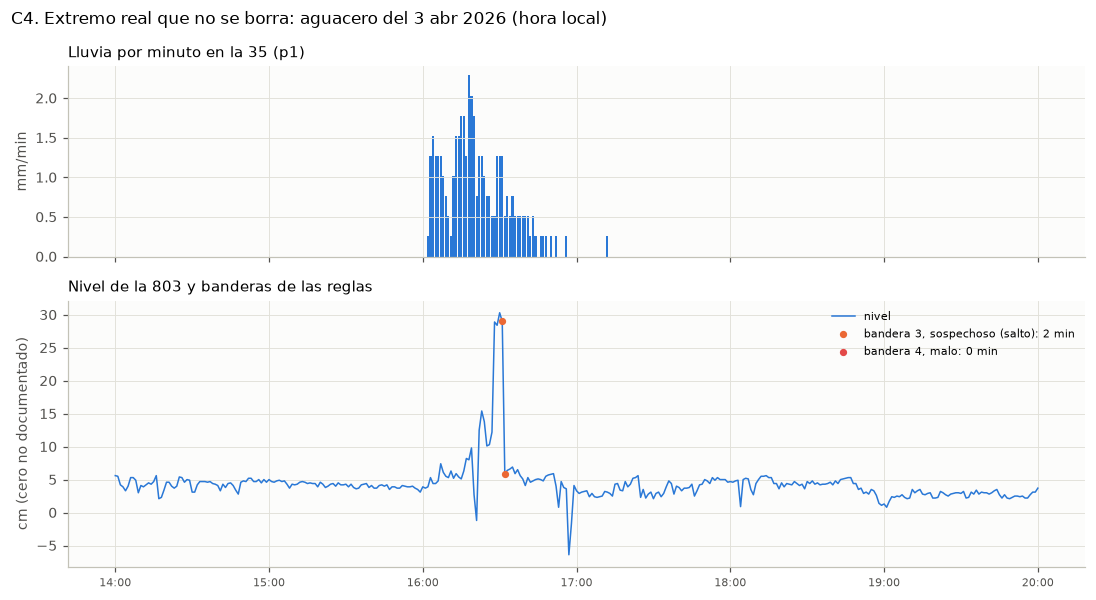

In [22]:
v = slice("2026-04-03 14:00", "2026-04-03 20:00")
fig, axs = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True, gridspec_kw={"height_ratios": [1, 1.4]})
lluvia_min = M["35"].loc[v, "p1"]
axs[0].bar(lluvia_min.index, lluvia_min, width=pd.Timedelta("50s"), color=AZUL)
axs[0].set_ylabel("mm/min"); axs[0].set_title("Lluvia por minuto en la 35 (p1)", loc="left")
n = m803.loc[v]
axs[1].plot(n.index, n["nivel"], color=AZUL, lw=1, label="nivel")
for b, color, nombre in ((Q.SOSPECHOSO, NARANJA, "bandera 3, sospechoso (salto)"), (Q.MALO, ROJO, "bandera 4, malo")):
    sel = n["b_nivel"] == b
    axs[1].scatter(n.index[sel], n.loc[sel, "nivel"], s=14, color=color, zorder=3, label=f"{nombre}: {int(sel.sum())} min")
axs[1].set_ylabel("cm (cero no documentado)"); axs[1].legend(fontsize=7.5, loc="upper right")
axs[1].set_title("Nivel de la 803 y banderas de las reglas", loc="left")
eje_fechas(axs[1], "hora")
fig.suptitle("C4. Extremo real que no se borra: aguacero del 3 abr 2026 (hora local)", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
guardar(fig, "c4_extremo_real")

### Tabla de eventos

Columnas: `codigo` (estación, texto), `variable`, `inicio` y `fin` (hora local), `duracion_min`, `tipo`, `detector`, `regla_o_modelo`, `severidad` y `descripcion`. La usa el dashboard como tabla filtrable.

In [23]:
COLUMNAS = ["codigo", "variable", "inicio", "fin", "duracion_min", "tipo", "detector", "regla_o_modelo", "severidad",
            "descripcion"]
EVENTOS = (pd.concat([ER[COLUMNAS], EMt[COLUMNAS], EC[COLUMNAS], ECONF[COLUMNAS]], ignore_index=True)
           .sort_values(["codigo", "inicio", "variable"]).reset_index(drop=True))
assert set(EVENTOS["tipo"]) <= set(A.TIPOS) and set(EVENTOS["severidad"]) <= {"alta", "media", "baja"}
assert EVENTOS[COLUMNAS].notna().all().all()
salida = EVENTOS.assign(codigo=EVENTOS["codigo"].astype(str), inicio=EVENTOS["inicio"].dt.strftime("%Y-%m-%d %H:%M"),
                        fin=EVENTOS["fin"].dt.strftime("%Y-%m-%d %H:%M"))
salida.to_csv(DIR_RES / "eventos_anomalias.csv", index=False)
print(len(EVENTOS), "eventos\n")
print(pd.crosstab(EVENTOS["tipo"], EVENTOS["severidad"], margins=True, margins_name="total").to_string(), "\n")
print(pd.crosstab([EVENTOS["codigo"], EVENTOS["detector"]], EVENTOS["tipo"]).to_string(), "\n")
print("Minutos por tipo y estación (suma de duraciones, sin las filas de configuración que cubren todo el periodo):")
print(EVENTOS[EVENTOS["tipo"] != "problema de configuración"]
      .pivot_table(index="codigo", columns="tipo", values="duracion_min", aggfunc="sum", fill_value=0).to_string())

815 eventos

severidad                  alta  baja  media  total
tipo                                               
evento físico real           17   180      0    197
falla de comunicación         1   203     46    250
falla de sensor              36   148    177    361
problema de configuración     4     0      3      7
total                        58   531    226    815 

tipo                                evento físico real  falla de comunicación  falla de sensor  problema de configuración
codigo detector                                                                                                          
35     columna calidad de SIATA                      0                      1                0                          0
       reglas deterministas                          0                      0               22                          0
367    Isolation Forest                             22                      0                0                          0
       STL 

In [24]:
# Eventos de severidad alta que no son de configuración, los más largos primero
alta = EVENTOS[(EVENTOS["severidad"] == "alta") & (EVENTOS["tipo"] != "problema de configuración")]
print(alta.sort_values("duracion_min", ascending=False).head(12)
      [["codigo", "variable", "inicio", "duracion_min", "tipo", "detector", "regla_o_modelo"]].to_string(index=False))

codigo variable              inicio  duracion_min                  tipo                 detector                    regla_o_modelo
    35    p1+p2 2025-12-14 09:37:00          2944 falla de comunicación columna calidad de SIATA                          código 2
   803    nivel 2025-12-03 14:42:00          1418       falla de sensor     reglas deterministas pico_sin_lluvia+rango_clima+salto
   803    nivel 2025-12-07 20:51:00          1351       falla de sensor     reglas deterministas pico_sin_lluvia+rango_clima+salto
   803    nivel 2025-12-02 22:41:00           455       falla de sensor     reglas deterministas pico_sin_lluvia+rango_clima+salto
   803    nivel 2026-03-13 04:13:00           431       falla de sensor     reglas deterministas pico_sin_lluvia+rango_clima+salto
   803    nivel 2026-03-14 19:05:00           405       falla de sensor     reglas deterministas                   pico_sin_lluvia
   803    nivel 2025-12-07 00:00:00           395       falla de sensor     reglas 

### Lectura de C4

- 815 eventos: 361 fallas de sensor, 250 de comunicación, 197 eventos físicos reales y 7 problemas de configuración; 58 de severidad alta.
- Lo que más pesa para las alertas: las mesetas del nivel de la 803 (fallas de sensor de hasta 1418 min), el tramo de 2944 min del 14 al 16 dic 2025 en que la 35 no llegó en tiempo real y cuatro problemas de configuración de severidad alta: la escala de la lluvia de la 367 (0,283 de la 35), el cero del nivel, el cambio del 3 mar en la 803 y el cambio del algoritmo de calidad de SIATA, que hace que la etiqueta no sea comparable entre meses.
- La 6004 tiene muchos huecos (207 eventos), casi todos cortos salvo el del 8 al 9 abr; la radiación no entra a las alertas y por eso quedan en baja o media.
- Los modelos dejan 142 eventos sin lluvia y sin falla de las reglas. No se clasifican ni entran a la tabla: quedan como lista de revisión.
- Ningún extremo real tiene un minuto malo: el aguacero del 3 abr (2 minutos sospechosos en el nivel, por el salto), los minutos de radiación sobre la extraterrestre (7 sospechosos de 1162, entre realce por nubes y luz de crepúsculo) y las subidas del nivel con lluvia (5 sospechosos de 1688). El pico del nivel del 3 abr deja una duda (un bloque de 4 min cerca de 30 cm que cae 23 cm en un minuto con lluvia intensa): se anota en la fila y se deja para revisión humana, sin borrar nada.

## C5. Esquema de banderas y diccionario de los códigos de SIATA

La OMM no tiene una guía estándar para definir banderas (WMO-No. 1269, 2021, sec. 2.4, nota 3, p. 4). Por eso se usa el esquema de la recomendación IOC/UNESCO (Manuals and Guides 54, vol. 3, 2013), pensado para intercambiar datos entre redes: 1 bueno, 2 no evaluado, 3 sospechoso, 4 malo, 9 faltante. Cada minuto lleva una bandera por variable (`b_<var>`) y una del registro (`b_registro`, la peor entre las variables con dato, comparable con `calidad`, que es por fila). Toda bandera deja traza en `fallas.parquet`: qué prueba la disparó y con qué severidad. Una bandera 3 o 4 no borra el valor; se conserva el original, como pide la misma sección de WMO-No. 1269.

In [25]:
pruebas_por_bandera = F.groupby("bandera")["prueba"].agg(lambda p: ", ".join(sorted(set(p))))
cuando = {Q.BUENO: "pasó todas las pruebas que le aplican",
          Q.NO_EVALUADO: "una prueba que le aplica no se pudo correr (en la 803, sin 3 h previas de lluvia de la 35 "
                         "o de historia del nivel)",
          Q.SOSPECHOSO: "falla una prueba de plausibilidad; se revisa antes de usar y no se borra",
          Q.MALO: "falla un límite físico, un salto imposible o una falla segura (viento en 0 en las cuatro columnas, "
                  "nivel 30 cm sobre la base sin lluvia); no entra a productos automáticos, se conserva",
          Q.FALTANTE: "no llegó el dato o llegó un centinela (-999 o -9999)"}
ESQUEMA = pd.DataFrame({"bandera": list(Q.NOMBRE_BANDERA), "nombre": list(Q.NOMBRE_BANDERA.values()),
                        "cuando": [cuando[b] for b in Q.NOMBRE_BANDERA],
                        "pruebas_en_la_traza": [pruebas_por_bandera.get(b, "ninguna") for b in Q.NOMBRE_BANDERA]})
for c in M:
    ESQUEMA[f"minutos_{c}"] = ESQUEMA["bandera"].map(M[c]["b_registro"].value_counts()).fillna(0).astype(int)
print(ESQUEMA.to_string(index=False))

 bandera      nombre                                                                                                                                                                                  cuando                                                                                                                                                  pruebas_en_la_traza  minutos_367  minutos_803  minutos_6004  minutos_35
       1       bueno                                                                                                                                                   pasó todas las pruebas que le aplican                                                                                                                                                              ninguna       211830       209424        214786      217186
       2 no evaluado                                                                      una prueba que le aplica no se pudo correr (en la 803, sin 3 h pre

### Diccionario inferido de la columna `calidad`

El diccionario oficial está en las guías de cada red, aparte de la ficha de cada estación. La ficha de la 6004 en datos.siata.gov.co documenta 1 (confiable en tiempo real), 151 (dudoso), 1581 (offset negativo de noche), 1582 (mayor a 0 de noche) y 1583 (supera la radiación teórica). El resto se infiere de los datos. Estructura inferida: primer dígito 1 = tiempo real, 2 = llegó después; luego 5 = dudoso y al final el número de la prueba (151 genérico, 154 humedad, 1502 y 1504 nivel, 1511 y 1512 lluvia, 1567 viento, 1581 a 1583 radiación). Por ejemplo, 251 sería un 151 que llegó después. Confianza: alta si el código está en la ficha o si la condición inferida se cumple en 95 % o más de sus minutos; media si se cumple entre 60 % y 95 % o si se infiere por analogía; baja si hay muy pocos minutos o la condición se cumple en menos de 60 %.

In [26]:
def confianza(pct=None, documentado=False, minutos=None):
    if documentado or (pct is not None and pct >= 95):
        return "alta"
    if minutos is not None and minutos < 10:
        return "baja"
    return "media" if pct is None or pct >= 60 else "baja"


desvio_1 = desvio[c803 == 1].median()
sin_lluvia_3h = lluvia_3h < 1
dic = []


def fila(codigo_calidad, estacion, cal, significado, evidencia, conf):
    dic.append({"codigo_calidad": codigo_calidad, "estacion": estacion, "minutos": int((cal == codigo_calidad).sum()),
                "significado_inferido": significado, "evidencia": evidencia, "confianza": conf})


for c, cal in (("367", c367), ("803", c803), ("6004", c6004), ("35", c35)):
    fila(1, c, cal, "Dato confiable en tiempo real (documentado en la ficha de la 6004)",
         f"{num(100 * (cal == 1).mean(), 1)} % de los minutos con registro", "alta")
def tramos(x):
    """Cuántos tramos de minutos contiguos forma una máscara."""
    t = x[x].index.to_series()
    return int((t.diff() != pd.Timedelta("1min")).sum())


fila(2, "35", c35, "Dato válido que llegó después, no en tiempo real (inferido; la ficha dice que el primer dígito 1 "
     "es tiempo real)", f"{tramos(c35 == 2)} tramo de {int((c35 == 2).sum())} min, del {fecha(c35[c35 == 2].index.min(), True)} "
     f"al {fecha(c35[c35 == 2].index.max(), True)}; valores sin otra marca", "media")
fila(2, "803", c803, "Igual que en la 35: dato que llegó después",
     f"{int((c803 == 2).sum())} min en {tramos(c803 == 2)} tramos, de {fecha(c803[c803 == 2].index.min())} a "
     f"{fecha(c803[c803 == 2].index.max())}; por analogía con la 35", "media")
x = c803 == 151
pct = 100 * (m803.loc[x, "nivel"] > 100).mean()
fila(151, "803", c803, "Dudoso genérico (ficha de la 6004); en la 803 marca las mesetas sin lluvia",
     f"{num(pct, 1)} % con nivel > 100 cm, {num(100 * m803.loc[x, 'b_nivel'].isin([Q.SOSPECHOSO, Q.MALO]).mean(), 1)} % "
     f"marcado también por las reglas y {num(100 * sin_lluvia_3h[x].mean(), 1)} % sin lluvia en la 35 en las 3 h previas",
     confianza(pct, documentado=True))
x = c35 == 151
pct = 100 * M["35"].loc[x, "centinela"].mean()
fila(151, "35", c35, "Dudoso genérico; en la 35 acompaña al centinela -999",
     f"{num(pct, 0)} % de sus {int(x.sum())} minutos traen -999", confianza(pct, documentado=True, minutos=int(x.sum())))
x = c803 == 251
pct = 100 * (m803.loc[x, "nivel"] > 100).mean()
fila(251, "803", c803, "151 que llegó después (meseta, no tiempo real)",
     f"solo en diciembre; {num(pct, 1)} % con nivel > 100 cm", confianza(pct))
fila(251, "35", c35, "151 que llegó después", "un minuto, en diciembre", "baja")
x = c367 == 154
pct = 100 * (m367.loc[x, "h"] == 100).mean()
fila(154, "367", c367, "Humedad en 100 % sostenida",
     f"{num(pct, 1)} % con h = 100; solo {int(x.sum())} de {int((m367['h'] == 100).sum())} minutos con h = 100 lo tienen "
     f"(etiqueta parcial)", confianza(pct))
x = c803 == 1502
fila(1502, "803", c803, "Pico pequeño frente a la vecindad (ruido)",
     f"desvío frente a la mediana móvil de 11 min: mediana {num(desvio[x].median(), 1)} cm, frente a "
     f"{num(desvio_1, 1)} cm con código 1", "media")
x = c803 == 1504
pct = 100 * (m803.loc[x, "nivel"] < 0).mean()
fila(1504, "803", c803, "Nivel negativo (solo se aplicó en diciembre)",
     f"{num(pct, 1)} % con nivel < 0; de enero a abril los negativos salen con 1", confianza(pct))
x = c803 == 2502
fila(2502, "803", c803, "1502 que llegó después",
     f"{num(100 * (x & (mes == 12)).sum() / x.sum(), 0)} % en diciembre; desvío mediano "
     f"{num(desvio[x].median(), 1)} cm", "media")
x = c367 == 1511
pct = 100 * (p001 & sin35)[x].mean()
fila(1511, "367", c367, "Lluvia mínima (0,01 mm) sin respaldo de la 35",
     f"{num(pct, 1)} % con p = 0,01 mm y p1 = p2 = 0 en la 35; aparece desde el {fecha(c367[x].index.min())}",
     confianza(pct))
for codigo_calidad, signo, texto in ((1511, 1, "p1 > p2"), (1512, -1, "p1 < p2")):
    x = c35 == codigo_calidad
    pct = 100 * (signo * (M["35"].loc[x, "p1"] - M["35"].loc[x, "p2"]) > 0).mean()
    fila(codigo_calidad, "35", c35, f"Balancines distintos en el minuto: {texto}", f"{num(pct, 1)} % cumple {texto}",
         confianza(pct))
fila(2512, "35", c35, "1512 que llegó después", "un minuto, en diciembre", "baja")
x = c367 == 1567
pct = 100 * ceros[x].mean()
fila(1567, "367", c367, "Viento en cero en vv, vv_max, dv y dv_max a la vez",
     f"{num(pct, 1)} % con las cuatro en 0, entre minutos con viento; {c367[x].index.normalize().nunique()} días, "
     f"{int((c367[x].index.normalize() == c367[x].index.normalize().value_counts().idxmax()).sum())} min el "
     f"{fecha(c367[x].index.normalize().value_counts().idxmax())}", confianza(pct))
fila(1581, "6004", c6004, "Offset negativo de noche (documentado en la ficha)",
     f"no aparece: la radiación mínima es {num(m6004['radiacion'].min(), 1)} W/m² (parece truncada en 0)", "alta")
fila(1582, "6004", c6004, "Mayor a 0 de noche (ficha), con una noche de reloj de 18:00 a 06:00 (inferido)",
     f"{num(pct_ventana, 0)} % entre 18:00 y 06:00; {num(pct_sol, 0)} % con el sol sobre el horizonte", "alta")
x = c6004 == 1583
pct = 100 * (m6004.loc[x, "radiacion"] > EXTRA[x]).mean()
fila(1583, "6004", c6004, "Supera la radiación teórica (ficha); la referencia no es la extraterrestre horizontal",
     f"{num(pct, 1)} % de sus minutos supera la extraterrestre horizontal; de los {int(sobre.sum())} minutos que la "
     f"superan, {int((sobre & x).sum())} tienen 1583", "alta")
DICCIONARIO = pd.DataFrame(dic)
DICCIONARIO["estacion"] = DICCIONARIO["estacion"].astype(str)
DICCIONARIO.to_csv(DIR_RES / "diccionario_calidad_inferido.csv", index=False)
print(DICCIONARIO.to_string(index=False))

 codigo_calidad estacion  minutos                                                                                             significado_inferido                                                                                                        evidencia confianza
              1      367   216712                                               Dato confiable en tiempo real (documentado en la ficha de la 6004)                                                                               99,7 % de los minutos con registro      alta
              1      803   191042                                               Dato confiable en tiempo real (documentado en la ficha de la 6004)                                                                               87,9 % de los minutos con registro      alta
              1     6004   213093                                               Dato confiable en tiempo real (documentado en la ficha de la 6004)                                            

### Contraste con el diccionario oficial

Después de inferir los códigos encontré las guías "Generalidades Repositorio de Datos" de cada red en datos.siata.gov.co, que traen el diccionario oficial. Se usan para contrastar la inferencia, no para reemplazarla.

In [27]:
# Diccionario oficial de SIATA: guías "Generalidades Repositorio de Datos" de cada red en datos.siata.gov.co
# (versión 01, 2024/11/25; aprobadas el 2025/12/04). Se encontraron después de inferir los códigos desde los datos,
# así que sirven para contrastar la inferencia.
GUIA = {"367": "P-GAA-SIATA-108, red meteorológica (doi:10.83041/NXHIKW), pp. 5-6",
        "803": "P-GAA-SIATA-110, red de nivel (doi:10.83041/5ZOUUO), p. 5",
        "6004": "P-GAA-SIATA-111, red de piranómetros (doi:10.83041/BD6U2H), p. 5",
        "35": "Guía de la red pluviométrica (doi:10.83041/JSGPWD), tabla 4"}
OFICIAL = {
    (1, None): "Calidad confiable del dato en tiempo real",
    (2, None): "Calidad confiable del dato no obtenido en tiempo real",
    (151, "803"): "Calidad dudosa del dato en tiempo real",
    (151, "35"): "Calidad dudosa del dato en tiempo real en ambos pluviómetros",
    (251, "803"): "Calidad dudosa en dato no obtenido en tiempo real",
    (251, "35"): "Calidad dudosa en dato no obtenido en tiempo real para ambos pluviómetros",
    (154, "367"): "Calidad dudosa en dato de humedad relativa (h) en tiempo real",
    (1502, "803"): "Calidad dudosa en dato por oscilaciones fuera de rango en tiempo real",
    (1504, "803"): "Repite la descripción del 1502 (error del diccionario); su par 2504 es degradación o gradación del lecho",
    (2502, "803"): "Calidad dudosa en dato no obtenido en tiempo real por oscilaciones fuera de rango",
    (1511, "367"): "Calidad dudosa en dato de precipitación (p) en tiempo real",
    (1511, "35"): "Calidad dudosa en dato del pluviómetro 1 (p1) en tiempo real",
    (1512, "35"): "Calidad dudosa en dato del pluviómetro 2 (p2) en tiempo real",
    (2512, "35"): "Calidad dudosa en dato no obtenido en tiempo real del pluviómetro 2 (p2)",
    (1567, "367"): "No está en la tabla: sale de la regla de combinación (p. 5): 156 magnitud del viento + 157 dirección del viento",
    (1581, "6004"): "Calidad dudosa por offset tipo A: valores menores a cero durante la noche",
    (1582, "6004"): "Calidad dudosa del dato por valores mayores a cero durante la noche",
    (1583, "6004"): "Calidad dudosa del dato por superar la radiación teórica",
}
# Juicio hecho a mano, código por código, comparando la columna significado_inferido con la oficial
COINCIDE = {(1567, "367"): "sí, por la regla de combinación de la guía (156 + 157)",
            (1504, "803"): "sí, con su par 2504 (el texto oficial del 1504 está duplicado)"}

dic = pd.read_csv(RAIZ / "parte2" / "resultados" / "diccionario_calidad_inferido.csv", dtype={"estacion": str})
dic["significado_oficial"] = [OFICIAL.get((c, e), OFICIAL.get((c, None))) for c, e in zip(dic["codigo_calidad"], dic["estacion"])]
dic["fuente_oficial"] = dic["estacion"].map(GUIA)
dic["coincide"] = [COINCIDE.get((c, e), "sí") for c, e in zip(dic["codigo_calidad"], dic["estacion"])]
dic.to_csv(RAIZ / "parte2" / "resultados" / "diccionario_calidad_inferido.csv", index=False)
presentes = dic[dic["minutos"] > 0]
print(f"códigos con datos: {len(presentes)}; la inferencia coincide con el diccionario oficial en "
      f"{presentes['coincide'].str.startswith('sí').sum()}")
dic[["codigo_calidad", "estacion", "minutos", "significado_inferido", "significado_oficial", "coincide"]]


códigos con datos: 21; la inferencia coincide con el diccionario oficial en 21


,codigo_calidad,estacion,minutos,significado_inferido,significado_oficial,coincide
0,1,367,216712,Dato confiable en tiempo real (documentado en la ficha de la 6004),Calidad confiable del dato en tiempo real,sí
1,1,803,191042,Dato confiable en tiempo real (documentado en la ficha de la 6004),Calidad confiable del dato en tiempo real,sí
2,1,6004,213093,Dato confiable en tiempo real (documentado en la ficha de la 6004),Calidad confiable del dato en tiempo real,sí
3,1,35,214388,Dato confiable en tiempo real (documentado en la ficha de la 6004),Calidad confiable del dato en tiempo real,sí
4,2,35,2944,"Dato válido que llegó después, no en tiempo real (inferido; la ficha dice que el primer dígito 1 es tiempo real)",Calidad confiable del dato no obtenido en tiempo real,sí
5,2,803,42,Igual que en la 35: dato que llegó después,Calidad confiable del dato no obtenido en tiempo real,sí
6,151,803,7955,Dudoso genérico (ficha de la 6004); en la 803 marca las mesetas sin lluvia,Calidad dudosa del dato en tiempo real,sí
7,151,35,9,Dudoso genérico; en la 35 acompaña al centinela -999,Calidad dudosa del dato en tiempo real en ambos pluviómetros,sí
8,251,803,394,"151 que llegó después (meseta, no tiempo real)",Calidad dudosa en dato no obtenido en tiempo real,sí
9,251,35,1,151 que llegó después,Calidad dudosa en dato no obtenido en tiempo real para ambos pluviómetros,sí


In [28]:
print(f"Tiempo total del notebook: {time.time() - T0:.0f} s")

Tiempo total del notebook: 12 s
